In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

import pandas as pd

df = pd.read_csv('/content/used_phone_price_prediction_1M (3) (1).csv')

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 28 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   brand                      1000000 non-null  object 
 1   model                      1000000 non-null  object 
 2   release_year               1000000 non-null  int64  
 3   ram_gb                     1000000 non-null  int64  
 4   storage_gb                 1000000 non-null  int64  
 5   screen_size_inches         1000000 non-null  float64
 6   battery_capacity           1000000 non-null  int64  
 7   processor_score            1000000 non-null  int64  
 8   camera_score               1000000 non-null  int64  
 9   os_type                    1000000 non-null  object 
 10  has_5g                     1000000 non-null  int64  
 11  original_price             1000000 non-null  int64  
 12  purchase_year              1000000 non-null  int64  
 13  age_months   

In [2]:
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000000, 28)


,brand,model,release_year,ram_gb,storage_gb,screen_size_inches,battery_capacity,processor_score,camera_score,os_type,...,body_damage,repair_history,water_damage,city_tier,seller_type,warranty_remaining_months,box_available,charger_available,market_demand_score,resale_price
0,Realme,Realme GT,2025,4,256,6.93,4130,47,100,Android,...,0,0,0,Tier1,Individual,11,1,1,99,47891.46
1,Samsung,Galaxy S21,2024,16,64,6.29,5558,81,67,Android,...,0,0,0,Tier3,Store,8,1,0,64,17663.21
2,Apple,iPhone 11,2022,4,128,5.52,5945,59,67,iOS,...,0,0,0,Tier1,Individual,0,0,1,68,67268.20
3,Google,Pixel 6,2024,16,512,5.99,5767,84,57,Android,...,0,0,1,Tier1,Store,11,1,1,50,12626.26
4,Google,Pixel 7,2021,4,128,6.59,5336,98,44,Android,...,0,0,0,Tier3,Store,24,1,1,66,20662.25


In [3]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,1000000,7,OnePlus,143120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,1000000,23,Vivo X90,71505,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,1000000.0,NaN,NaN,NaN,2022.001836,2.001558,2019.0,2020.0,2022.0,2024.0,2025.0
ram_gb,1000000.0,NaN,NaN,NaN,9.201878,4.309755,4.0,6.0,8.0,12.0,16.0
storage_gb,1000000.0,NaN,NaN,NaN,396.798912,349.40176,64.0,128.0,256.0,512.0,1024.0
screen_size_inches,1000000.0,NaN,NaN,NaN,6.25037,0.4329,5.5,5.88,6.25,6.63,7.0
battery_capacity,1000000.0,NaN,NaN,NaN,4750.004425,1009.971322,3000.0,3877.0,4750.0,5623.0,6500.0
processor_score,1000000.0,NaN,NaN,NaN,70.018905,17.600272,40.0,55.0,70.0,85.0,100.0
camera_score,1000000.0,NaN,NaN,NaN,69.980058,17.607651,40.0,55.0,70.0,85.0,100.0
os_type,1000000,2,Android,857310,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
quality = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
})
display(quality)
print("Duplicate rows:", df.duplicated().sum())


,data_type,missing,missing_%,unique_values
brand,object,0,0.0,7
model,object,0,0.0,23
release_year,int64,0,0.0,7
ram_gb,int64,0,0.0,5
storage_gb,int64,0,0.0,5
screen_size_inches,float64,0,0.0,151
battery_capacity,int64,0,0.0,3501
processor_score,int64,0,0.0,61
camera_score,int64,0,0.0,61
os_type,object,0,0.0,2


Duplicate rows: 0


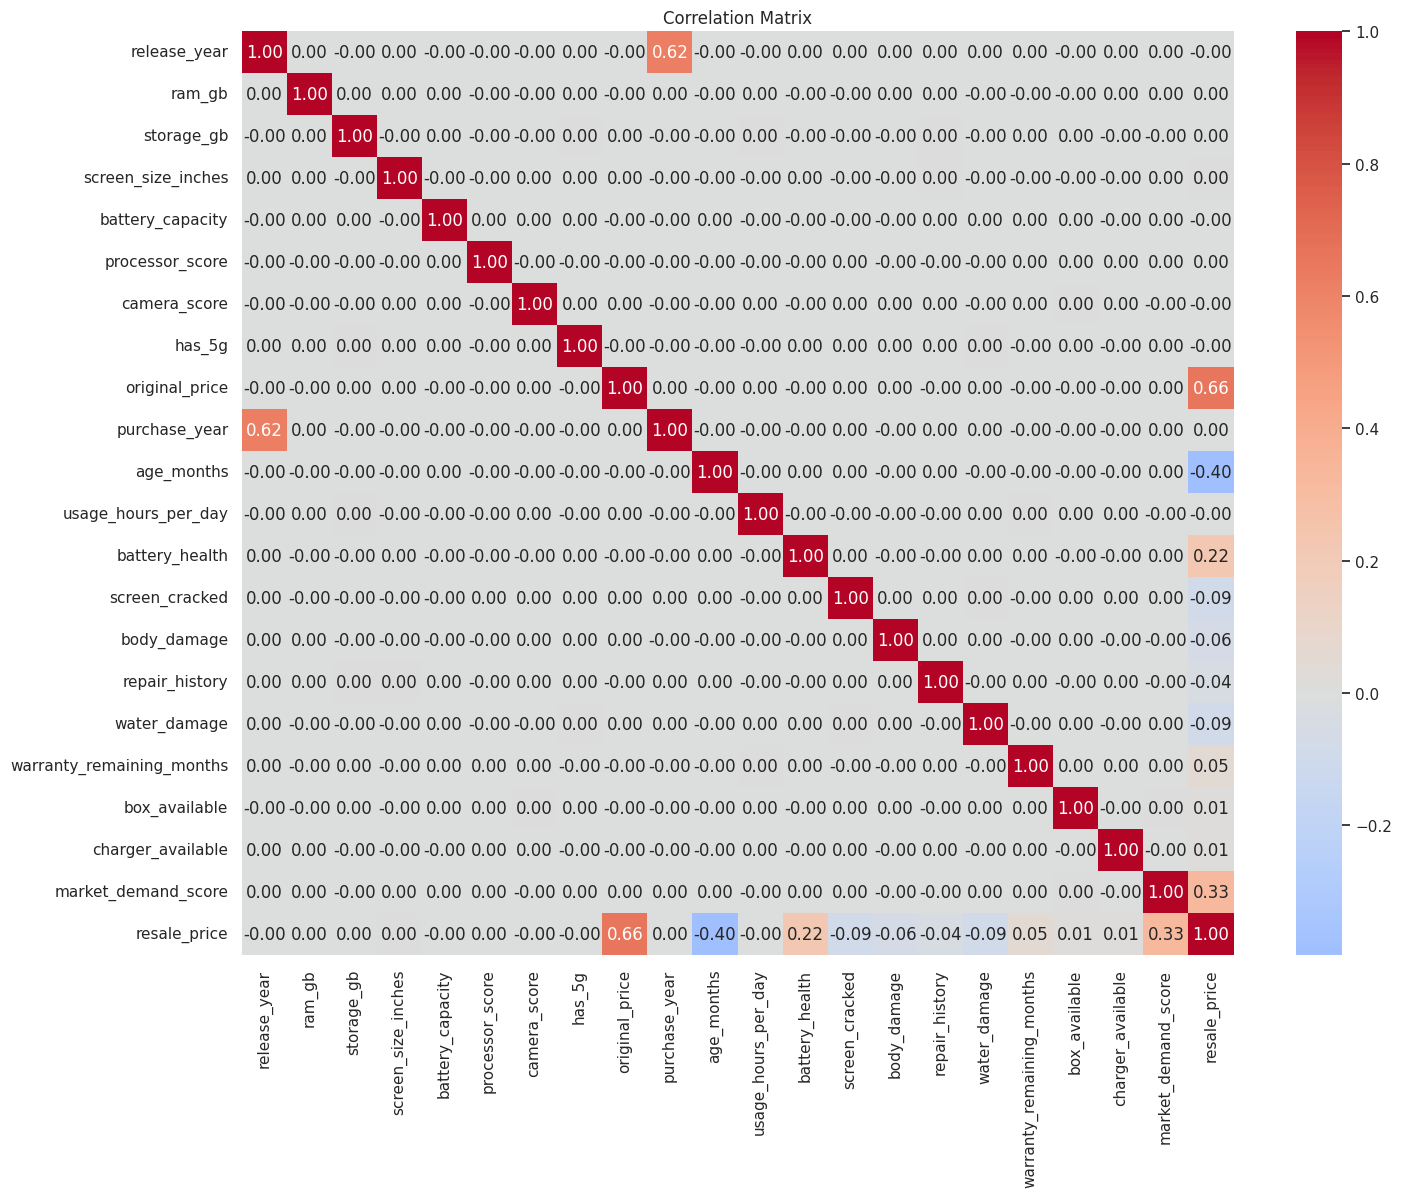

In [5]:
# Get only numerical columns from the dataframe
numeric_cols = df.select_dtypes(include='number').columns

correlation = df[numeric_cols].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.show()

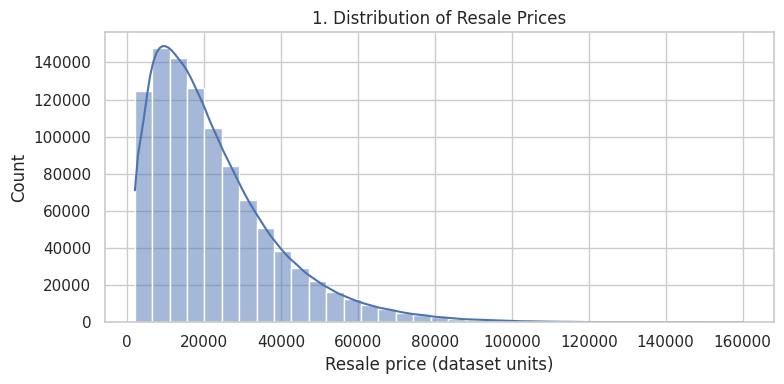

In [6]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="resale_price", bins=35, kde=True)
plt.title("1. Distribution of Resale Prices")
plt.xlabel("Resale price (dataset units)")
plt.tight_layout()
plt.show()


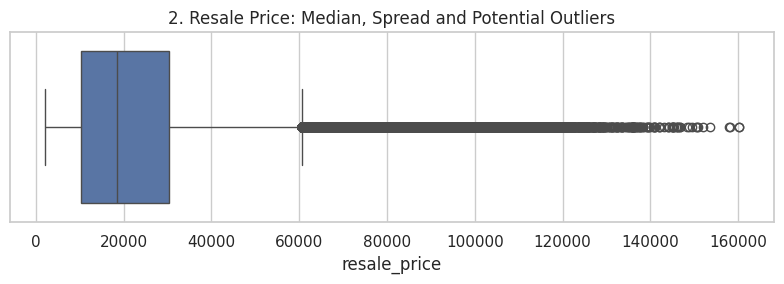

In [7]:
plt.figure(figsize=(8,3))
sns.boxplot(data=df, x="resale_price")
plt.title("2. Resale Price: Median, Spread and Potential Outliers")
plt.tight_layout()
plt.show()


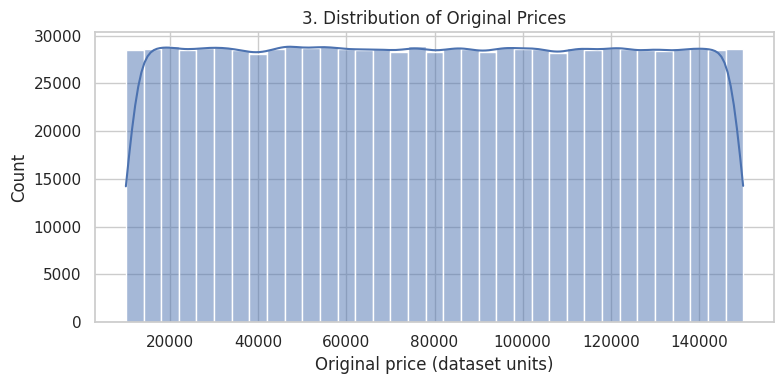

In [8]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="original_price", bins=35, kde=True)
plt.title("3. Distribution of Original Prices")
plt.xlabel("Original price (dataset units)")
plt.tight_layout()
plt.show()


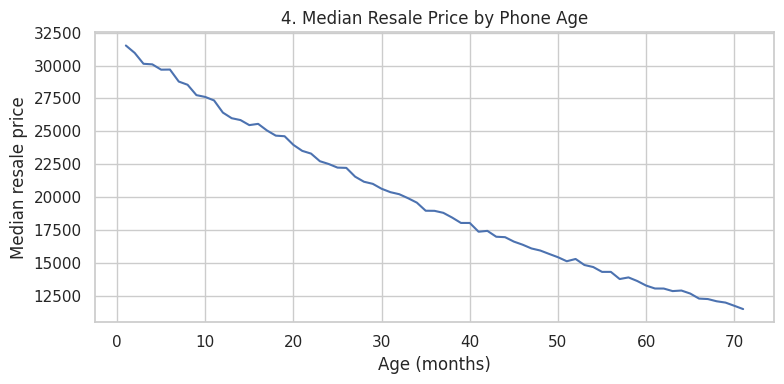

In [9]:
age_median = df.groupby("age_months", as_index=False)["resale_price"].median()
plt.figure(figsize=(8,4))
sns.lineplot(data=age_median, x="age_months", y="resale_price")
plt.title("4. Median Resale Price by Phone Age")
plt.xlabel("Age (months)")
plt.ylabel("Median resale price")
plt.tight_layout()
plt.show()


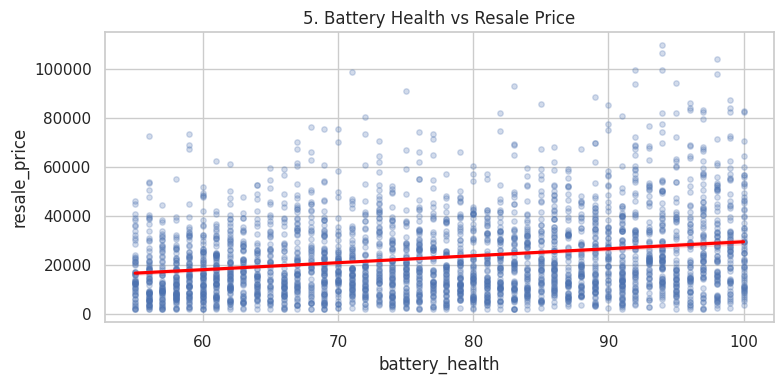

In [10]:
plt.figure(figsize=(8,4))
sns.regplot(data=df.sample(min(3000, len(df)), random_state=42),
            x="battery_health", y="resale_price",
            scatter_kws={"alpha":0.25, "s":15}, line_kws={"color":"red"})
plt.title("5. Battery Health vs Resale Price")
plt.tight_layout()
plt.show()


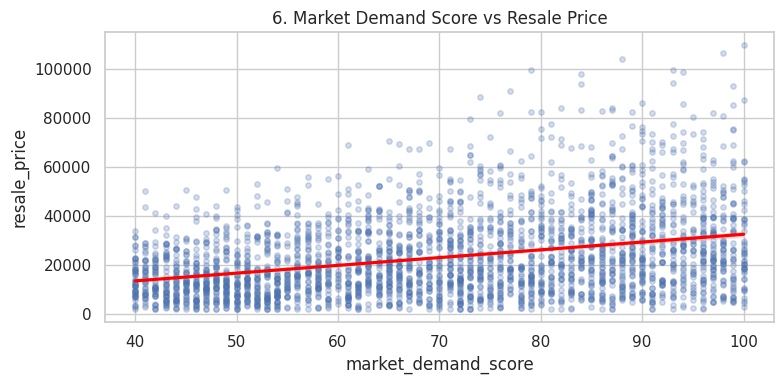

In [11]:
plt.figure(figsize=(8,4))
sns.regplot(data=df.sample(min(3000, len(df)), random_state=42),
            x="market_demand_score", y="resale_price",
            scatter_kws={"alpha":0.25, "s":15}, line_kws={"color":"red"})
plt.title("6. Market Demand Score vs Resale Price")
plt.tight_layout()
plt.show()


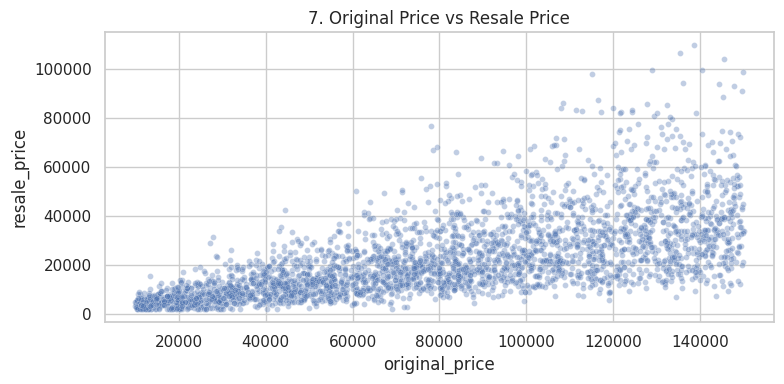

In [12]:
plt.figure(figsize=(8,4))
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=42),
                x="original_price", y="resale_price", alpha=0.35, s=18)
plt.title("7. Original Price vs Resale Price")
plt.tight_layout()
plt.show()


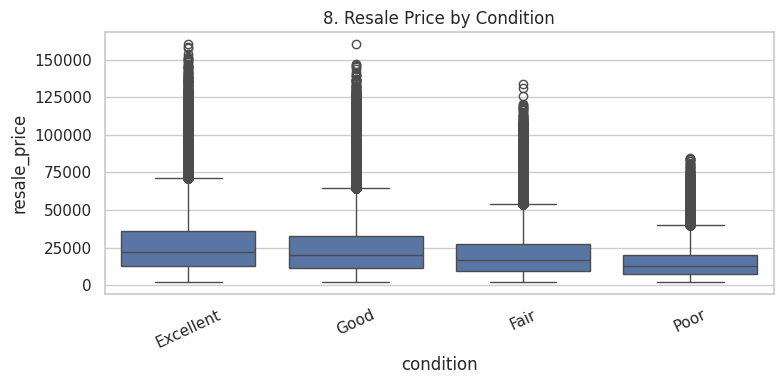

In [13]:
condition_order = df.groupby("condition")["resale_price"].median().sort_values(ascending=False).index
plt.figure(figsize=(8,4))
sns.boxplot(data=df, x="condition", y="resale_price", order=condition_order)
plt.title("8. Resale Price by Condition")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


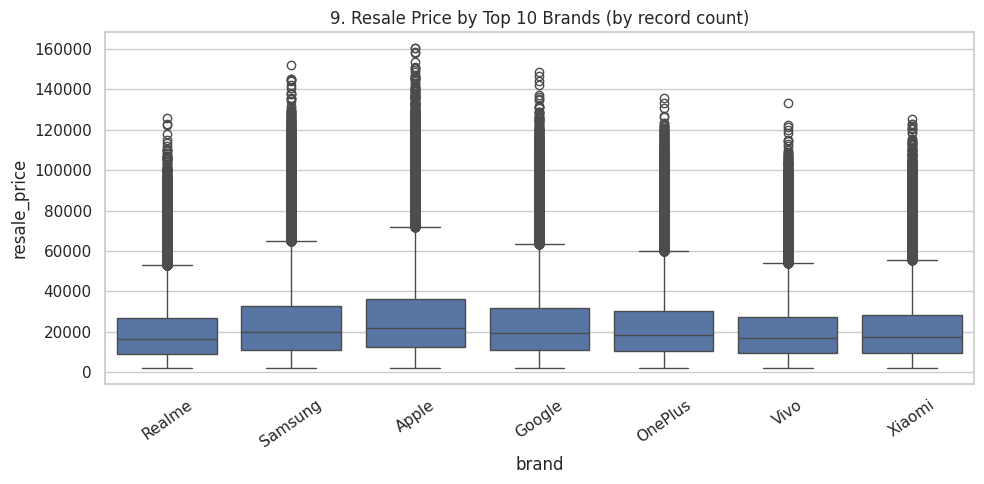

In [14]:
top_brands = df["brand"].value_counts().head(10).index
plt.figure(figsize=(10,5))
sns.boxplot(data=df[df["brand"].isin(top_brands)], x="brand", y="resale_price")
plt.title("9. Resale Price by Top 10 Brands (by record count)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


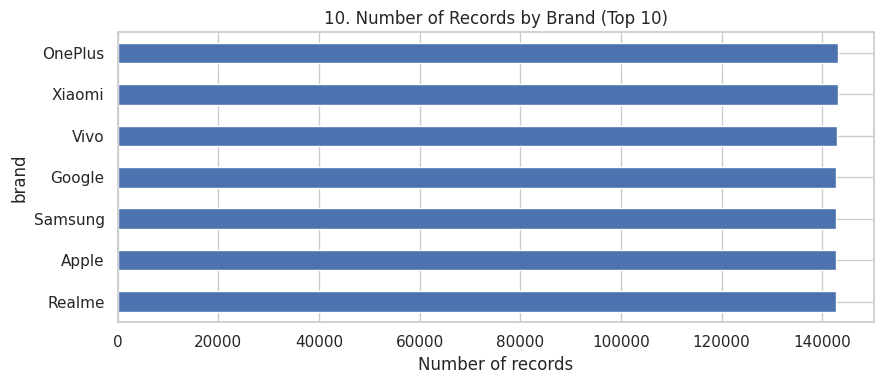

In [15]:
plt.figure(figsize=(9,4))
df["brand"].value_counts().head(10).sort_values().plot(kind="barh")
plt.title("10. Number of Records by Brand (Top 10)")
plt.xlabel("Number of records")
plt.tight_layout()
plt.show()


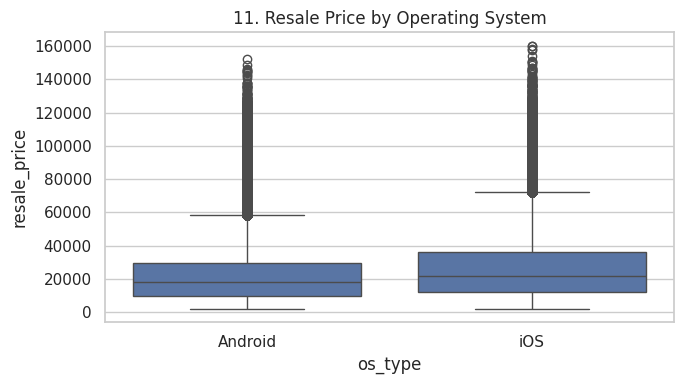

In [16]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="os_type", y="resale_price")
plt.title("11. Resale Price by Operating System")
plt.tight_layout()
plt.show()


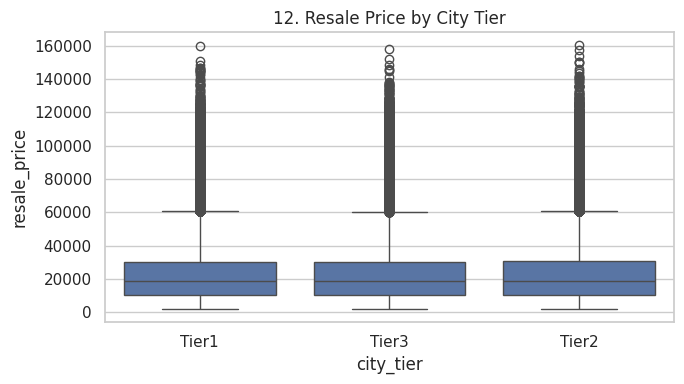

In [17]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="city_tier", y="resale_price")
plt.title("12. Resale Price by City Tier")
plt.tight_layout()
plt.show()


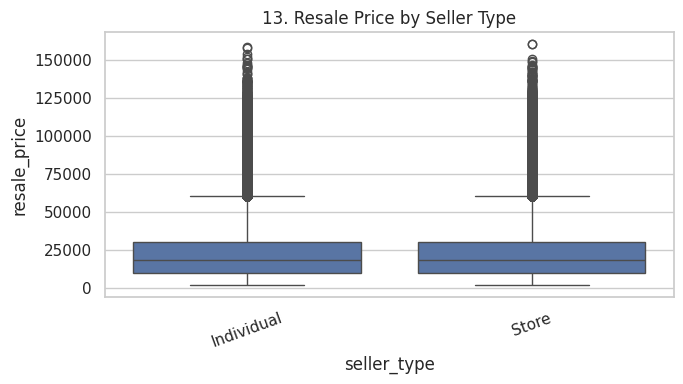

In [18]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="seller_type", y="resale_price")
plt.title("13. Resale Price by Seller Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


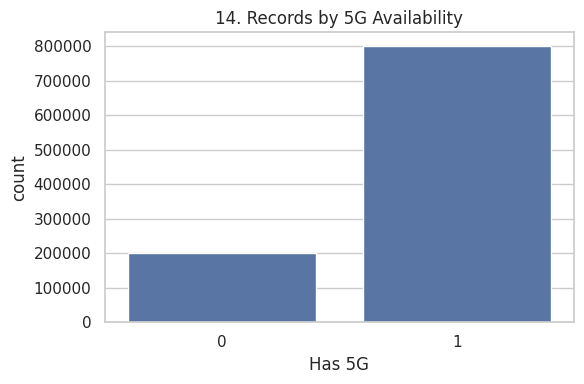

In [19]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="has_5g")
plt.title("14. Records by 5G Availability")
plt.xlabel("Has 5G")
plt.tight_layout()
plt.show()


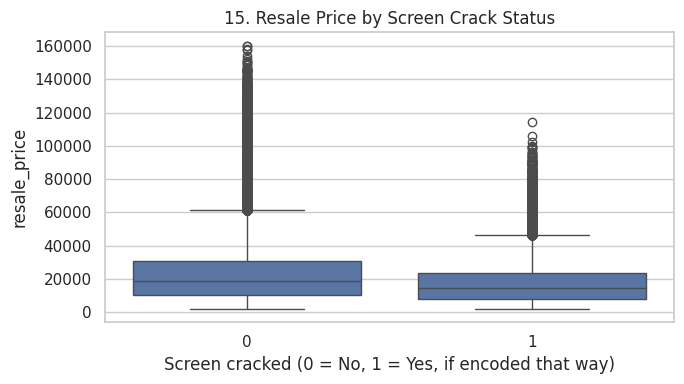

In [20]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="screen_cracked", y="resale_price")
plt.title("15. Resale Price by Screen Crack Status")
plt.xlabel("Screen cracked (0 = No, 1 = Yes, if encoded that way)")
plt.tight_layout()
plt.show()


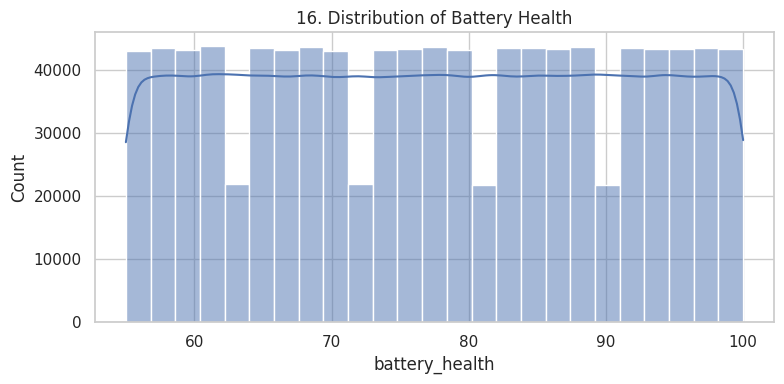

In [21]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="battery_health", bins=25, kde=True)
plt.title("16. Distribution of Battery Health")
plt.tight_layout()
plt.show()


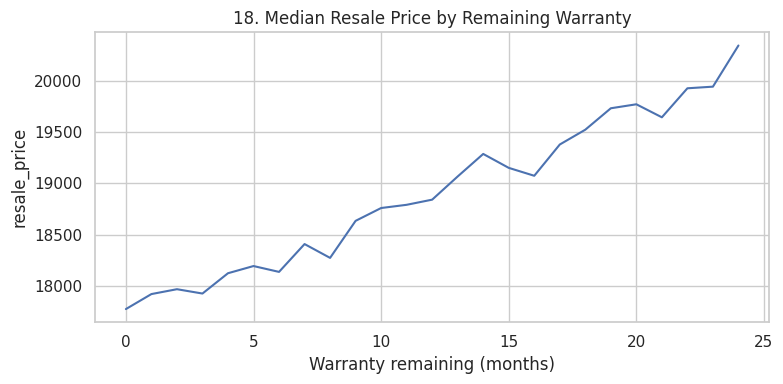

In [22]:
if "warranty_remaining_months" in df.columns:
    warranty_median = df.groupby("warranty_remaining_months", as_index=False)["resale_price"].median()
    plt.figure(figsize=(8,4))
    sns.lineplot(data=warranty_median, x="warranty_remaining_months", y="resale_price")
    plt.title("18. Median Resale Price by Remaining Warranty")
    plt.xlabel("Warranty remaining (months)")
    plt.tight_layout()
    plt.show()


In [23]:

# Fast and simple model training

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import numpy as np
import time

# Select features and target
drop_cols = ['resale_price', 'resale_ratio', 'age_group', 'demand_group']
X = df.drop(columns=drop_cols, errors='ignore')
y = df['resale_price']

# Use a smaller sample to finish faster
sample = df.sample(n=min(10000, len(df)), random_state=42)
X = sample.drop(columns=drop_cols, errors='ignore')
y = sample['resale_price']

# Identify numeric and categorical columns
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(exclude='number').columns

preprocess = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    ), cat_cols)
])

model = make_pipeline(preprocess, LinearRegression())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

start = time.time()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Model: Linear Regression")
print("Training and prediction time:", round(time.time() - start, 2), "seconds")
print("MAE:", round(mean_absolute_error(y_test, pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 2))
print("R² Score:", round(r2_score(y_test, pred), 3))


Model: Linear Regression
Training and prediction time: 0.11 seconds
MAE: 4476.3
RMSE: 6340.28
R² Score: 0.849


In [24]:
# Quick feature sensitivity check (no retraining)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

feature_sets = {
    "All features": [],
    "Without market_demand_score": ["market_demand_score"],
    "Without original_price": ["original_price"],
    "Without both": ["original_price", "market_demand_score"]
}

results = []

for label, drop_cols in feature_sets.items():
    X_check = X_test.copy()

    for col in drop_cols:
        if col in X_check.columns:
            if pd.api.types.is_numeric_dtype(X_train[col]):
                X_check[col] = X_train[col].median()
            else:
                X_check[col] = X_train[col].mode().iloc[0]

    pred = model.predict(X_check)

    results.append({
        "Features": label,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

display(pd.DataFrame(results).round(3))

,Features,MAE,RMSE,R2
0,All features,4476.300,6340.279,0.849
1,Without market_demand_score,6401.511,8621.981,0.721
2,Without original_price,9833.297,12546.979,0.409
3,Without both,10630.888,13827.105,0.283


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Classification Accuracy: 0.763

Classification Report:

              precision    recall  f1-score   support

        High       0.81      0.83      0.82     66667
         Low       0.82      0.83      0.82     66667
      Medium       0.65      0.63      0.64     66666

    accuracy                           0.76    200000
   macro avg       0.76      0.76      0.76    200000
weighted avg       0.76      0.76      0.76    200000



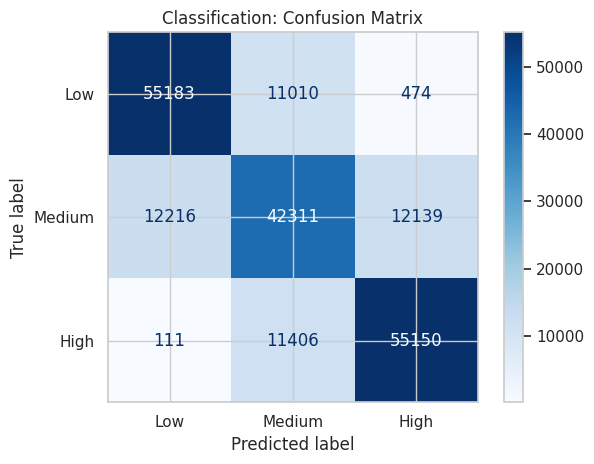

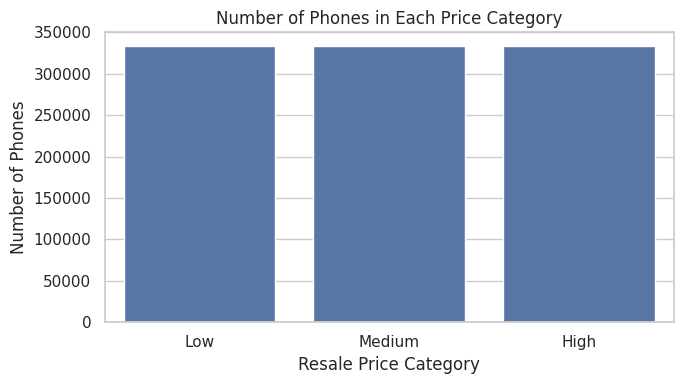

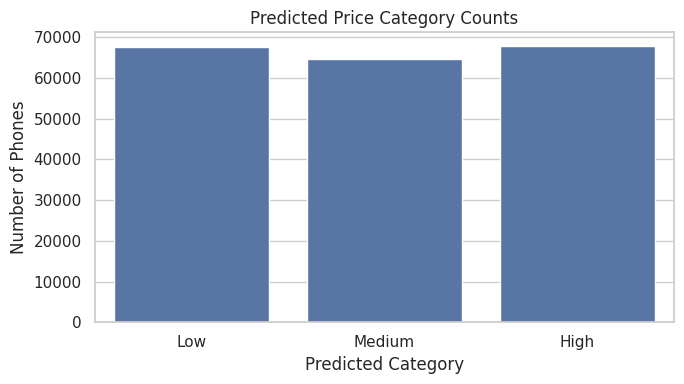

In [25]:

# Classification Model and Visualizations

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Drop rows with missing resale_price first to prevent NaN in target
class_df = df.dropna(subset=["resale_price"]).copy()

# Create price categories using tertiles
class_df["price_category"] = pd.qcut(
    class_df["resale_price"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

# Exclude target and helper columns from input features
Xc = class_df.drop(
    columns=["resale_price", "price_category",
             "resale_ratio", "age_group", "demand_group"],
    errors="ignore"
)
yc = class_df["price_category"]

# Split data
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

num_cols = Xc_train.select_dtypes(include="number").columns
cat_cols = Xc_train.select_dtypes(exclude="number").columns

prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore", max_categories=30)
    ), cat_cols)
])

clf = make_pipeline(
    prep,
    LogisticRegression(max_iter=200, solver="lbfgs")
)

clf.fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)

print("Classification Accuracy:", round(accuracy_score(yc_test, yc_pred), 3))
print("\nClassification Report:\n")
print(classification_report(yc_test, yc_pred, zero_division=0))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    yc_test, yc_pred,
    labels=["Low", "Medium", "High"],
    cmap="Blues"
)
plt.title("Classification: Confusion Matrix")
plt.tight_layout()
plt.show()

# 2. Actual Category Counts
plt.figure(figsize=(7, 4))
sns.countplot(x=yc, order=["Low", "Medium", "High"])
plt.title("Number of Phones in Each Price Category")
plt.xlabel("Resale Price Category")
plt.ylabel("Number of Phones")
plt.tight_layout()
plt.show()

# 3. Predicted Category Counts
plt.figure(figsize=(7, 4))
sns.countplot(x=pd.Series(yc_pred), order=["Low", "Medium", "High"])
plt.title("Predicted Price Category Counts")
plt.xlabel("Predicted Category")
plt.ylabel("Number of Phones")
plt.tight_layout()
plt.show()


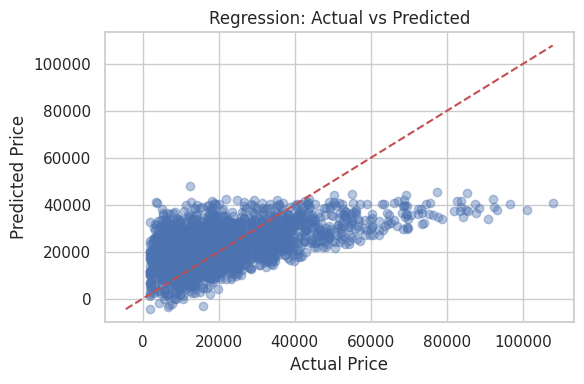

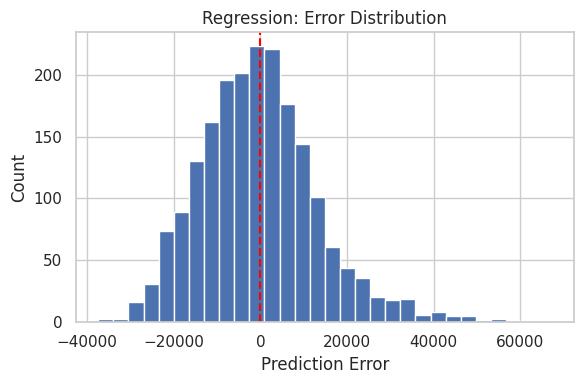

In [26]:

import matplotlib.pyplot as plt

# Actual vs predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred, alpha=0.4)
low = min(y_test.min(), pred.min())
high = max(y_test.max(), pred.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

# Prediction errors
residuals = y_test - pred
plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=30)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Prediction Error")
plt.ylabel("Count")
plt.title("Regression: Error Distribution")
plt.tight_layout()
plt.show()


REGRESSION RESULTS
MAE  : 4742.64
RMSE : 6509.26
R²   : 0.843


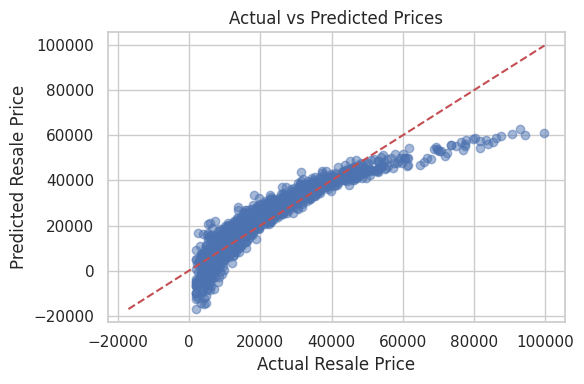

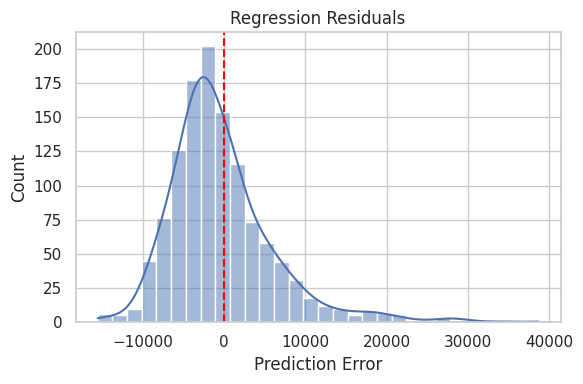

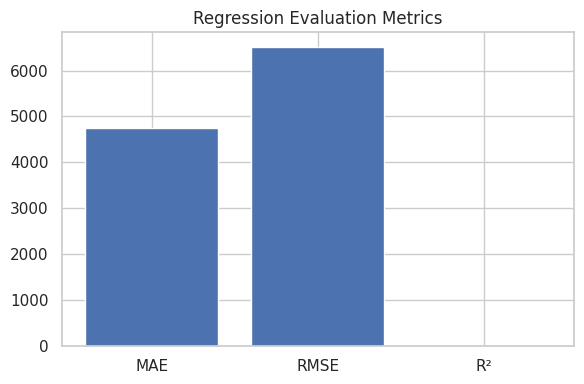

In [27]:

# REGRESSION MODEL + VISUALIZATIONS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use a smaller sample for faster training
data_reg = df.sample(n=min(6000, len(df)), random_state=42).copy()
data_reg = data_reg.drop(
    columns=["resale_ratio", "age_group", "demand_group"],
    errors="ignore"
)

X = data_reg.drop(columns=["resale_price"])
y = data_reg["resale_price"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore", max_categories=20
        ))
    ]), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

reg_model = Pipeline([
    ("prep", prep),
    ("model", Ridge(alpha=1.0))
])

reg_model.fit(X_train, y_train)
reg_pred = reg_model.predict(X_test)

mae = mean_absolute_error(y_test, reg_pred)
rmse = np.sqrt(mean_squared_error(y_test, reg_pred))
r2 = r2_score(y_test, reg_pred)

print("REGRESSION RESULTS")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")

# Plot 1: Actual vs predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test, reg_pred, alpha=0.5)
low = min(y_test.min(), reg_pred.min())
high = max(y_test.max(), reg_pred.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Resale Price")
plt.ylabel("Predicted Resale Price")
plt.title("Actual vs Predicted Prices")
plt.tight_layout()
plt.show()

# Plot 2: Residual distribution
residuals = y_test - reg_pred
plt.figure(figsize=(6, 4))
sns.histplot(residuals, bins=30, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Prediction Error")
plt.title("Regression Residuals")
plt.tight_layout()
plt.show()

# Plot 3: Evaluation metrics
plt.figure(figsize=(6, 4))
plt.bar(["MAE", "RMSE", "R²"], [mae, rmse, r2])
plt.title("Regression Evaluation Metrics")
plt.tight_layout()
plt.show()


CLASSIFICATION METRICS


,Metric,Score
0,Accuracy,0.810
1,Precision,0.811
2,Recall,0.810
3,F1 Score,0.801


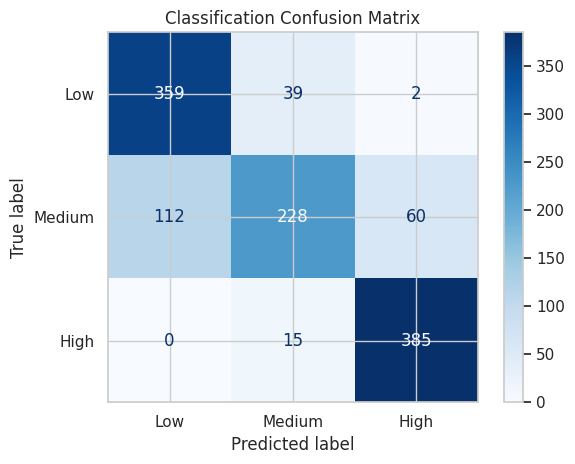

In [28]:

# CLASSIFICATION MODEL: CONFUSION MATRIX + METRICS TABLE

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay
)

# Use a sample for faster training
data_clf = df.sample(n=min(6000, len(df)), random_state=42).copy()
data_clf = data_clf.drop(
    columns=["resale_ratio", "age_group", "demand_group"],
    errors="ignore"
)

# Create Low, Medium, High price categories
yc = pd.qcut(
    data_clf["resale_price"],
    q=3,
    labels=["Low", "Medium", "High"]
)

Xc = data_clf.drop(columns=["resale_price"])

num_cols = Xc.select_dtypes(include="number").columns.tolist()
cat_cols = Xc.select_dtypes(exclude="number").columns.tolist()

prep_clf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore", max_categories=20
        ))
    ]), cat_cols)
])

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

clf = Pipeline([
    ("prep", prep_clf),
    ("model", LogisticRegression(max_iter=150, solver="liblinear"))
])

clf.fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)

# Metrics table
metrics_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [
        accuracy_score(yc_test, yc_pred),
        precision_score(yc_test, yc_pred, average="weighted",
                        zero_division=0),
        recall_score(yc_test, yc_pred, average="weighted",
                     zero_division=0),
        f1_score(yc_test, yc_pred, average="weighted",
                 zero_division=0)
    ]
})

print("CLASSIFICATION METRICS")
display(metrics_table.round(3))

# Confusion matrix only
ConfusionMatrixDisplay.from_predictions(
    yc_test, yc_pred,
    labels=["Low", "Medium", "High"],
    cmap="Blues"
)
plt.title("Classification Confusion Matrix")
plt.tight_layout()
plt.show()


In [29]:
import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
from PIL import Image

# Helper to convert matplotlib figures to images for Gradio
def fig_to_img(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format='png', bbox_inches='tight')
    buf.seek(0)
    plt.close(fig)
    return Image.open(buf)

# Generate static visualization figures
def get_vis1():
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(data=df.sample(20000, random_state=42), x="resale_price", bins=35, kde=True, ax=ax)
    ax.set_title("Distribution of Resale Prices")
    return fig_to_img(fig)

def get_vis2():
    fig, ax = plt.subplots(figsize=(8, 4))
    age_median = df.groupby("age_months", as_index=False)["resale_price"].median()
    sns.lineplot(data=age_median, x="age_months", y="resale_price", ax=ax)
    ax.set_title("Median Resale Price by Phone Age (Months)")
    return fig_to_img(fig)

def get_vis3():
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=df, x="condition", y="resale_price", ax=ax)
    ax.set_title("Resale Price by Condition")
    return fig_to_img(fig)

# Prediction function matching the pipeline features
def predict_price(brand, model_name, release_year, ram_gb, storage_gb, screen_size_inches,
                  battery_capacity, processor_score, camera_score, os_type, has_5g,
                  original_price, purchase_year, age_months, usage_hours_per_day,
                  condition, battery_health, screen_cracked, body_damage,
                  repair_history, water_damage, city_tier, seller_type,
                  warranty_remaining_months, box_available, charger_available,
                  market_demand_score):

    input_data = pd.DataFrame([{
        'brand': brand,
        'model': model_name,
        'release_year': int(release_year),
        'ram_gb': int(ram_gb),
        'storage_gb': int(storage_gb),
        'screen_size_inches': float(screen_size_inches),
        'battery_capacity': int(battery_capacity),
        'processor_score': int(processor_score),
        'camera_score': int(camera_score),
        'os_type': os_type,
        'has_5g': int(1 if has_5g == 'Yes' else 0),
        'original_price': int(original_price),
        'purchase_year': int(purchase_year),
        'age_months': int(age_months),
        'usage_hours_per_day': float(usage_hours_per_day),
        'condition': condition,
        'battery_health': int(battery_health),
        'screen_cracked': int(1 if screen_cracked == 'Yes' else 0),
        'body_damage': int(body_damage),
        'repair_history': int(repair_history),
        'water_damage': int(1 if water_damage == 'Yes' else 0),
        'city_tier': city_tier,
        'seller_type': seller_type,
        'warranty_remaining_months': int(warranty_remaining_months),
        'box_available': int(1 if box_available == 'Yes' else 0),
        'charger_available': int(1 if charger_available == 'Yes' else 0),
        'market_demand_score': int(market_demand_score)
    }])

    # Use our trained regression model for prediction
    predicted = reg_model.predict(input_data)[0]
    return f"₹{max(0.0, round(predicted, 2)):,}"

# Dynamic choices based on dataset
brand_list = sorted(df['brand'].unique().tolist())
cond_list = sorted(df['condition'].unique().tolist())
os_list = sorted(df['os_type'].unique().tolist())
city_list = sorted(df['city_tier'].unique().tolist())
seller_list = sorted(df['seller_type'].unique().tolist())

# Helper to filter models based on selected brand
def update_models(brand):
    filtered_models = sorted(df[df['brand'] == brand]['model'].unique().tolist())
    return gr.update(choices=filtered_models, value=filtered_models[0] if filtered_models else None)

# Setup layout without custom colors
with gr.Blocks() as demo:
    gr.Markdown("# 📱 Used Phone Resale Valuation Dashboard")

    with gr.Tab("💸 Price Predictor"):
        gr.Markdown("### Adjust the specifications below to compute the real-time valuation of the phone.")

        with gr.Row():
            with gr.Column():
                brand = gr.Dropdown(choices=brand_list, value="Apple", label="Brand")
                model_dropdown = gr.Dropdown(choices=sorted(df[df['brand'] == "Apple"]['model'].unique().tolist()), value="iPhone 13" if "iPhone 13" in df['model'].values else None, label="Model")
                os_type = gr.Dropdown(choices=os_list, value="iOS", label="OS Type")
                condition = gr.Dropdown(choices=cond_list, value="Excellent", label="Physical Condition")
                original_price = gr.Slider(minimum=5000, maximum=150000, value=50000, step=1000, label="Original Price (units)")
                battery_health = gr.Slider(minimum=50, maximum=100, value=90, step=1, label="Battery Health (%)")
                age_months = gr.Slider(minimum=1, maximum=72, value=12, step=1, label="Age (Months)")

            with gr.Column():
                ram_gb = gr.Dropdown(choices=[4, 6, 8, 12, 16, 24], value=8, label="RAM (GB)")
                storage_gb = gr.Dropdown(choices=[64, 128, 256, 512, 1024], value=128, label="Storage (GB)")
                release_year = gr.Number(value=2022, precision=0, label="Release Year")
                purchase_year = gr.Number(value=2022, precision=0, label="Purchase Year")
                screen_size_inches = gr.Slider(minimum=4.0, maximum=7.5, value=6.1, step=0.1, label="Screen Size (Inches)")
                battery_capacity = gr.Slider(minimum=2000, maximum=6000, value=4000, step=100, label="Battery Capacity (mAh)")

            with gr.Column():
                processor_score = gr.Slider(minimum=10, maximum=100, value=75, step=1, label="Processor Score")
                camera_score = gr.Slider(minimum=10, maximum=100, value=80, step=1, label="Camera Score")
                usage_hours_per_day = gr.Slider(minimum=0.5, maximum=15.0, value=4.5, step=0.5, label="Daily Usage Hours")
                warranty_remaining_months = gr.Slider(minimum=0, maximum=24, value=6, step=1, label="Warranty Remaining (Months)")
                market_demand_score = gr.Slider(minimum=10, maximum=100, value=85, step=1, label="Market Demand Score")
                city_tier = gr.Dropdown(choices=city_list, value="Tier1", label="City Tier")

            with gr.Column():
                seller_type = gr.Dropdown(choices=seller_list, value="Individual", label="Seller Type")
                has_5g = gr.Radio(choices=["Yes", "No"], value="Yes", label="Has 5G?")
                screen_cracked = gr.Radio(choices=["Yes", "No"], value="No", label="Is Screen Cracked?")
                body_damage = gr.Slider(minimum=0, maximum=10, value=1, step=1, label="Body Damage Score (0=None)")
                repair_history = gr.Slider(minimum=0, maximum=5, value=0, step=1, label="Number of Repairs")
                water_damage = gr.Radio(choices=["Yes", "No"], value="No", label="Water Damage?")
                box_available = gr.Radio(choices=["Yes", "No"], value="Yes", label="Box Available?")
                charger_available = gr.Radio(choices=["Yes", "No"], value="Yes", label="Charger Available?")

        # Update the model selection dropdown when the brand dropdown changes
        brand.change(fn=update_models, inputs=brand, outputs=model_dropdown)

        with gr.Row():
            predict_btn = gr.Button("Calculate Resale Price", variant="primary")
            output_price = gr.Textbox(label="Estimated Resale Value", placeholder="Calculated value...")

        predict_btn.click(
            fn=predict_price,
            inputs=[brand, model_dropdown, release_year, ram_gb, storage_gb, screen_size_inches,
                    battery_capacity, processor_score, camera_score, os_type, has_5g,
                    original_price, purchase_year, age_months, usage_hours_per_day,
                    condition, battery_health, screen_cracked, body_damage,
                    repair_history, water_damage, city_tier, seller_type,
                    warranty_remaining_months, box_available, charger_available,
                    market_demand_score],
            outputs=output_price
        )

    with gr.Tab("📊 Visualizations"):
        gr.Markdown("### Key Dataset Insights")
        with gr.Row():
            vis1 = gr.Image(value=get_vis1(), label="Price Distribution")
            vis2 = gr.Image(value=get_vis2(), label="Price Depreciation by Age")
        with gr.Row():
            vis3 = gr.Image(value=get_vis3(), label="Price by Device Condition")

    with gr.Tab("📁 Dataset Preview"):
        gr.Markdown("### Previewing the original 1 Million records dataset")
        gr.DataFrame(value=df.head(100), interactive=False)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://655afdbbac05942136.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [30]:
# ---- Run this in Google Colab (one cell, after uploading the CSV) ----
import json, joblib, sklearn
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

CSV = "/content/used_phone_price_prediction_1M (3) (1).csv"   # change if your file name differs
df = pd.read_csv(CSV)

# helper / leaky columns + very high-cardinality 'model' are dropped
drop_cols = ["resale_ratio", "age_group", "demand_group", "model"]
data = df.sample(n=min(100_000, len(df)), random_state=42).drop(columns=drop_cols, errors="ignore")

X = data.drop(columns=["resale_price"])
y = data["resale_price"]
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
model = Pipeline([("prep", prep), ("model", Ridge(alpha=1.0))])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, pred), 2), "| R2:", round(r2_score(y_test, pred), 3))

# Save the model + form metadata (dropdown options, numeric ranges) for the web app
meta = {"cat": {c: sorted(X[c].dropna().unique().tolist()) for c in cat_cols}, "num": {}}
for c in num_cols:
    meta["num"][c] = {"min": float(X[c].min()), "max": float(X[c].max()),
                      "default": float(X[c].median()), "binary": bool(X[c].nunique() <= 2)}
meta["columns"] = X.columns.tolist()

joblib.dump(model, "model.joblib", compress=3)
json.dump(meta, open("meta.json", "w"))
print("scikit-learn version to pin in requirements.txt:", sklearn.__version__)

from google.colab import files
files.download("model.joblib"); files.download("meta.json")

MAE: 4797.95 | R2: 0.833
scikit-learn version to pin in requirements.txt: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
# ---- Run this as a NEW cell in the same Colab notebook (after train_model.py) ----
import json
from google.colab import files

drop = ["resale_ratio", "age_group", "demand_group"]
s = df.drop(columns=drop, errors="ignore").sample(200, random_state=1)
extras = {
    "sample": json.loads(s.to_json(orient="records")),
    "brand_avg": df.groupby("brand")["resale_price"].mean().round(0).sort_values(ascending=False).head(12).to_dict(),
    "condition_avg": df.groupby("condition")["resale_price"].mean().round(0).to_dict(),
    "age_avg": df.assign(b=(df["age_months"] // 12 * 12)).groupby("b")["resale_price"].mean().round(0).to_dict(),
}
json.dump(extras, open("extras.json", "w"))
files.download("extras.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
{"sample": [{"brand": "OnePlus", "model": "OnePlus 9", "release_year": 2024, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 5.55, "battery_capacity": 6464, "processor_score": 48, "camera_score": 66, "os_type": "Android", "has_5g": 0, "original_price": 34741, "purchase_year": 2024, "age_months": 52, "usage_hours_per_day": 2.1, "condition": "Fair", "battery_health": 85, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 1, "box_available": 1, "charger_available": 1, "market_demand_score": 79, "resale_price": 8054.66}, {"brand": "Vivo", "model": "Vivo V27", "release_year": 2025, "ram_gb": 16, "storage_gb": 256, "screen_size_inches": 6.11, "battery_capacity": 4376, "processor_score": 60, "camera_score": 80, "os_type": "Android", "has_5g": 1, "original_price": 146945, "purchase_year": 2025, "age_months": 37, "usage_hours_per_day": 9.7, "condition": "Poor", "battery_health": 59, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 14, "box_available": 1, "charger_available": 0, "market_demand_score": 95, "resale_price": 26270.09}, {"brand": "Samsung", "model": "Galaxy S23", "release_year": 2025, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 5.86, "battery_capacity": 3733, "processor_score": 89, "camera_score": 73, "os_type": "Android", "has_5g": 1, "original_price": 114038, "purchase_year": 2025, "age_months": 20, "usage_hours_per_day": 4.5, "condition": "Excellent", "battery_health": 83, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 17, "box_available": 0, "charger_available": 1, "market_demand_score": 89, "resale_price": 69162.0}, {"brand": "Samsung", "model": "Galaxy S22", "release_year": 2019, "ram_gb": 6, "storage_gb": 1024, "screen_size_inches": 6.0, "battery_capacity": 4204, "processor_score": 55, "camera_score": 69, "os_type": "Android", "has_5g": 0, "original_price": 85048, "purchase_year": 2019, "age_months": 60, "usage_hours_per_day": 6.4, "condition": "Fair", "battery_health": 94, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 9, "box_available": 1, "charger_available": 1, "market_demand_score": 45, "resale_price": 15119.93}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2024, "ram_gb": 6, "storage_gb": 128, "screen_size_inches": 6.68, "battery_capacity": 3908, "processor_score": 78, "camera_score": 67, "os_type": "Android", "has_5g": 1, "original_price": 114939, "purchase_year": 2024, "age_months": 31, "usage_hours_per_day": 6.9, "condition": "Good", "battery_health": 57, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 9, "box_available": 1, "charger_available": 1, "market_demand_score": 94, "resale_price": 31367.75}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2025, "ram_gb": 6, "storage_gb": 512, "screen_size_inches": 6.07, "battery_capacity": 5115, "processor_score": 60, "camera_score": 66, "os_type": "Android", "has_5g": 1, "original_price": 54089, "purchase_year": 2025, "age_months": 12, "usage_hours_per_day": 11.5, "condition": "Good", "battery_health": 91, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 1, "box_available": 1, "charger_available": 1, "market_demand_score": 76, "resale_price": 32496.79}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2022, "ram_gb": 12, "storage_gb": 512, "screen_size_inches": 6.02, "battery_capacity": 5067, "processor_score": 53, "camera_score": 93, "os_type": "Android", "has_5g": 1, "original_price": 31314, "purchase_year": 2022, "age_months": 67, "usage_hours_per_day": 10.6, "condition": "Good", "battery_health": 82, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 74, "resale_price": 3362.85}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2023, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.83, "battery_capacity": 6355, "processor_score": 89, "camera_score": 56, "os_type": "Android", "has_5g": 1, "original_price": 124922, "purchase_year": 2025, "age_months": 4, "usage_hours_per_day": 11.5, "condition": "Good", "battery_health": 85, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 13, "box_available": 1, "charger_available": 1, "market_demand_score": 93, "resale_price": 88098.28}, {"brand": "OnePlus", "model": "OnePlus 10", "release_year": 2019, "ram_gb": 4, "storage_gb": 512, "screen_size_inches": 6.9, "battery_capacity": 4908, "processor_score": 68, "camera_score": 41, "os_type": "Android", "has_5g": 1, "original_price": 24971, "purchase_year": 2022, "age_months": 60, "usage_hours_per_day": 6.5, "condition": "Excellent", "battery_health": 78, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 12, "box_available": 1, "charger_available": 0, "market_demand_score": 40, "resale_price": 2179.83}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2023, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 6.11, "battery_capacity": 4130, "processor_score": 51, "camera_score": 67, "os_type": "Android", "has_5g": 1, "original_price": 144996, "purchase_year": 2023, "age_months": 52, "usage_hours_per_day": 6.5, "condition": "Excellent", "battery_health": 61, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 9, "box_available": 1, "charger_available": 1, "market_demand_score": 76, "resale_price": 28208.97}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2021, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 6.84, "battery_capacity": 5876, "processor_score": 88, "camera_score": 67, "os_type": "Android", "has_5g": 1, "original_price": 63498, "purchase_year": 2025, "age_months": 18, "usage_hours_per_day": 11.8, "condition": "Fair", "battery_health": 99, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 4, "box_available": 1, "charger_available": 1, "market_demand_score": 93, "resale_price": 36946.22}, {"brand": "Vivo", "model": "Vivo V27", "release_year": 2021, "ram_gb": 6, "storage_gb": 512, "screen_size_inches": 6.51, "battery_capacity": 3239, "processor_score": 92, "camera_score": 86, "os_type": "Android", "has_5g": 1, "original_price": 108157, "purchase_year": 2022, "age_months": 49, "usage_hours_per_day": 6.8, "condition": "Good", "battery_health": 58, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 76, "resale_price": 18846.4}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2019, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.5, "battery_capacity": 4473, "processor_score": 61, "camera_score": 43, "os_type": "Android", "has_5g": 1, "original_price": 139201, "purchase_year": 2022, "age_months": 29, "usage_hours_per_day": 7.3, "condition": "Poor", "battery_health": 65, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 16, "box_available": 1, "charger_available": 1, "market_demand_score": 74, "resale_price": 23550.58}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2023, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 5.86, "battery_capacity": 4900, "processor_score": 57, "camera_score": 81, "os_type": "Android", "has_5g": 1, "original_price": 90033, "purchase_year": 2023, "age_months": 65, "usage_hours_per_day": 2.6, "condition": "Excellent", "battery_health": 73, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 21, "box_available": 0, "charger_available": 1, "market_demand_score": 57, "resale_price": 17124.01}, {"brand": "Samsung", "model": "Galaxy S22", "release_year": 2021, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.82, "battery_capacity": 4581, "processor_score": 82, "camera_score": 75, "os_type": "Android", "has_5g": 1, "original_price": 133013, "purchase_year": 2023, "age_months": 25, "usage_hours_per_day": 11.1, "condition": "Fair", "battery_health": 85, "screen_cracked": 1, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 1, "box_available": 0, "charger_available": 1, "market_demand_score": 78, "resale_price": 37452.15}, {"brand": "Samsung", "model": "Galaxy S23", "release_year": 2020, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 6.03, "battery_capacity": 4387, "processor_score": 78, "camera_score": 92, "os_type": "Android", "has_5g": 0, "original_price": 76242, "purchase_year": 2020, "age_months": 15, "usage_hours_per_day": 8.7, "condition": "Good", "battery_health": 71, "screen_cracked": 1, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 22, "box_available": 1, "charger_available": 1, "market_demand_score": 66, "resale_price": 20619.28}, {"brand": "Google", "model": "Pixel 6", "release_year": 2024, "ram_gb": 4, "storage_gb": 128, "screen_size_inches": 6.65, "battery_capacity": 5720, "processor_score": 43, "camera_score": 96, "os_type": "Android", "has_5g": 1, "original_price": 15887, "purchase_year": 2025, "age_months": 68, "usage_hours_per_day": 5.4, "condition": "Good", "battery_health": 72, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 23, "box_available": 0, "charger_available": 1, "market_demand_score": 77, "resale_price": 4112.12}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2021, "ram_gb": 16, "storage_gb": 128, "screen_size_inches": 6.1, "battery_capacity": 3571, "processor_score": 59, "camera_score": 75, "os_type": "Android", "has_5g": 1, "original_price": 110073, "purchase_year": 2024, "age_months": 26, "usage_hours_per_day": 6.8, "condition": "Good", "battery_health": 96, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 21, "box_available": 1, "charger_available": 1, "market_demand_score": 86, "resale_price": 55374.5}, {"brand": "Realme", "model": "Realme GT", "release_year": 2023, "ram_gb": 4, "storage_gb": 128, "screen_size_inches": 6.27, "battery_capacity": 4586, "processor_score": 46, "camera_score": 47, "os_type": "Android", "has_5g": 1, "original_price": 34583, "purchase_year": 2024, "age_months": 19, "usage_hours_per_day": 2.2, "condition": "Good", "battery_health": 75, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 20, "box_available": 1, "charger_available": 1, "market_demand_score": 89, "resale_price": 12945.95}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2024, "ram_gb": 12, "storage_gb": 256, "screen_size_inches": 6.69, "battery_capacity": 3597, "processor_score": 99, "camera_score": 40, "os_type": "Android", "has_5g": 1, "original_price": 82293, "purchase_year": 2024, "age_months": 7, "usage_hours_per_day": 3.2, "condition": "Good", "battery_health": 58, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 22, "box_available": 1, "charger_available": 1, "market_demand_score": 41, "resale_price": 18447.93}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2023, "ram_gb": 8, "storage_gb": 256, "screen_size_inches": 5.89, "battery_capacity": 6264, "processor_score": 65, "camera_score": 83, "os_type": "Android", "has_5g": 1, "original_price": 94115, "purchase_year": 2023, "age_months": 25, "usage_hours_per_day": 2.7, "condition": "Good", "battery_health": 82, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 98, "resale_price": 43355.8}, {"brand": "Google", "model": "Pixel 6", "release_year": 2022, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 5.93, "battery_capacity": 5818, "processor_score": 56, "camera_score": 88, "os_type": "Android", "has_5g": 0, "original_price": 14128, "purchase_year": 2025, "age_months": 46, "usage_hours_per_day": 7.5, "condition": "Good", "battery_health": 63, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 19, "box_available": 1, "charger_available": 1, "market_demand_score": 40, "resale_price": 4343.1}, {"brand": "Apple", "model": "iPhone 14", "release_year": 2021, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.56, "battery_capacity": 5785, "processor_score": 71, "camera_score": 78, "os_type": "iOS", "has_5g": 1, "original_price": 47696, "purchase_year": 2024, "age_months": 31, "usage_hours_per_day": 11.4, "condition": "Fair", "battery_health": 62, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 17, "box_available": 1, "charger_available": 1, "market_demand_score": 45, "resale_price": 7718.86}, {"brand": "OnePlus", "model": "OnePlus 10", "release_year": 2025, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 5.73, "battery_capacity": 4965, "processor_score": 51, "camera_score": 67, "os_type": "Android", "has_5g": 1, "original_price": 111614, "purchase_year": 2025, "age_months": 25, "usage_hours_per_day": 11.1, "condition": "Fair", "battery_health": 66, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 7, "box_available": 0, "charger_available": 1, "market_demand_score": 95, "resale_price": 29375.4}, {"brand": "OnePlus", "model": "OnePlus 10", "release_year": 2025, "ram_gb": 12, "storage_gb": 128, "screen_size_inches": 6.43, "battery_capacity": 5759, "processor_score": 46, "camera_score": 87, "os_type": "Android", "has_5g": 1, "original_price": 101858, "purchase_year": 2025, "age_months": 41, "usage_hours_per_day": 7.1, "condition": "Fair", "battery_health": 61, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 78, "resale_price": 23893.67}, {"brand": "Google", "model": "Pixel 8", "release_year": 2025, "ram_gb": 6, "storage_gb": 1024, "screen_size_inches": 6.87, "battery_capacity": 5914, "processor_score": 78, "camera_score": 61, "os_type": "Android", "has_5g": 0, "original_price": 119403, "purchase_year": 2025, "age_months": 18, "usage_hours_per_day": 4.9, "condition": "Fair", "battery_health": 81, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 81, "resale_price": 46040.59}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2020, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 6.57, "battery_capacity": 4238, "processor_score": 72, "camera_score": 90, "os_type": "Android", "has_5g": 1, "original_price": 48700, "purchase_year": 2025, "age_months": 44, "usage_hours_per_day": 2.2, "condition": "Good", "battery_health": 61, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 77, "resale_price": 4580.17}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2024, "ram_gb": 16, "storage_gb": 128, "screen_size_inches": 6.9, "battery_capacity": 4677, "processor_score": 86, "camera_score": 63, "os_type": "Android", "has_5g": 1, "original_price": 21555, "purchase_year": 2024, "age_months": 9, "usage_hours_per_day": 6.9, "condition": "Excellent", "battery_health": 85, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 21, "box_available": 0, "charger_available": 1, "market_demand_score": 63, "resale_price": 14896.72}, {"brand": "Vivo", "model": "Vivo V27", "release_year": 2021, "ram_gb": 16, "storage_gb": 64, "screen_size_inches": 6.5, "battery_capacity": 3023, "processor_score": 75, "camera_score": 57, "os_type": "Android", "has_5g": 1, "original_price": 143377, "purchase_year": 2023, "age_months": 64, "usage_hours_per_day": 1.5, "condition": "Good", "battery_health": 83, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 4, "box_available": 1, "charger_available": 0, "market_demand_score": 75, "resale_price": 28544.33}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2020, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 5.62, "battery_capacity": 3191, "processor_score": 72, "camera_score": 66, "os_type": "Android", "has_5g": 0, "original_price": 69841, "purchase_year": 2020, "age_months": 50, "usage_hours_per_day": 8.2, "condition": "Fair", "battery_health": 87, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 16, "box_available": 0, "charger_available": 1, "market_demand_score": 68, "resale_price": 14402.75}, {"brand": "Google", "model": "Pixel 7", "release_year": 2020, "ram_gb": 12, "storage_gb": 128, "screen_size_inches": 6.47, "battery_capacity": 5662, "processor_score": 97, "camera_score": 77, "os_type": "Android", "has_5g": 1, "original_price": 68264, "purchase_year": 2025, "age_months": 30, "usage_hours_per_day": 5.0, "condition": "Fair", "battery_health": 78, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 3, "box_available": 1, "charger_available": 1, "market_demand_score": 97, "resale_price": 25159.89}, {"brand": "Vivo", "model": "Vivo V27", "release_year": 2023, "ram_gb": 8, "storage_gb": 64, "screen_size_inches": 5.79, "battery_capacity": 4904, "processor_score": 66, "camera_score": 50, "os_type": "Android", "has_5g": 0, "original_price": 109882, "purchase_year": 2024, "age_months": 35, "usage_hours_per_day": 4.4, "condition": "Excellent", "battery_health": 75, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 3, "box_available": 1, "charger_available": 1, "market_demand_score": 87, "resale_price": 40084.73}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2025, "ram_gb": 12, "storage_gb": 128, "screen_size_inches": 6.66, "battery_capacity": 3227, "processor_score": 99, "camera_score": 60, "os_type": "Android", "has_5g": 1, "original_price": 148282, "purchase_year": 2025, "age_months": 13, "usage_hours_per_day": 6.9, "condition": "Good", "battery_health": 80, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 15, "box_available": 1, "charger_available": 1, "market_demand_score": 57, "resale_price": 54392.47}, {"brand": "Realme", "model": "Realme GT", "release_year": 2019, "ram_gb": 16, "storage_gb": 256, "screen_size_inches": 6.6, "battery_capacity": 4282, "processor_score": 50, "camera_score": 52, "os_type": "Android", "has_5g": 1, "original_price": 67831, "purchase_year": 2025, "age_months": 32, "usage_hours_per_day": 6.3, "condition": "Good", "battery_health": 70, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 18, "box_available": 0, "charger_available": 1, "market_demand_score": 81, "resale_price": 21236.49}, {"brand": "Apple", "model": "iPhone 13", "release_year": 2022, "ram_gb": 6, "storage_gb": 512, "screen_size_inches": 5.54, "battery_capacity": 6370, "processor_score": 62, "camera_score": 51, "os_type": "iOS", "has_5g": 1, "original_price": 60017, "purchase_year": 2023, "age_months": 47, "usage_hours_per_day": 5.3, "condition": "Good", "battery_health": 86, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 11, "box_available": 0, "charger_available": 1, "market_demand_score": 67, "resale_price": 20956.1}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2021, "ram_gb": 16, "storage_gb": 1024, "screen_size_inches": 5.58, "battery_capacity": 3423, "processor_score": 62, "camera_score": 97, "os_type": "Android", "has_5g": 1, "original_price": 49605, "purchase_year": 2024, "age_months": 40, "usage_hours_per_day": 12.0, "condition": "Excellent", "battery_health": 70, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 11, "box_available": 1, "charger_available": 0, "market_demand_score": 90, "resale_price": 20843.12}, {"brand": "OnePlus", "model": "OnePlus 11", "release_year": 2022, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 6.51, "battery_capacity": 3506, "processor_score": 41, "camera_score": 67, "os_type": "Android", "has_5g": 0, "original_price": 104764, "purchase_year": 2023, "age_months": 19, "usage_hours_per_day": 5.9, "condition": "Good", "battery_health": 68, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 7, "box_available": 1, "charger_available": 1, "market_demand_score": 77, "resale_price": 41616.72}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2020, "ram_gb": 12, "storage_gb": 256, "screen_size_inches": 6.7, "battery_capacity": 3543, "processor_score": 45, "camera_score": 47, "os_type": "Android", "has_5g": 1, "original_price": 121151, "purchase_year": 2025, "age_months": 8, "usage_hours_per_day": 1.3, "condition": "Fair", "battery_health": 86, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 22, "box_available": 1, "charger_available": 0, "market_demand_score": 43, "resale_price": 28062.96}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2022, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.14, "battery_capacity": 3852, "processor_score": 77, "camera_score": 91, "os_type": "Android", "has_5g": 0, "original_price": 84252, "purchase_year": 2024, "age_months": 53, "usage_hours_per_day": 11.3, "condition": "Excellent", "battery_health": 92, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 17, "box_available": 0, "charger_available": 0, "market_demand_score": 49, "resale_price": 17422.02}, {"brand": "Google", "model": "Pixel 6", "release_year": 2022, "ram_gb": 4, "storage_gb": 128, "screen_size_inches": 6.79, "battery_capacity": 5786, "processor_score": 57, "camera_score": 42, "os_type": "Android", "has_5g": 1, "original_price": 114541, "purchase_year": 2022, "age_months": 67, "usage_hours_per_day": 6.2, "condition": "Good", "battery_health": 100, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 17, "box_available": 1, "charger_available": 0, "market_demand_score": 54, "resale_price": 22962.96}, {"brand": "Realme", "model": "Realme GT", "release_year": 2019, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 6.97, "battery_capacity": 5475, "processor_score": 53, "camera_score": 62, "os_type": "Android", "has_5g": 1, "original_price": 90810, "purchase_year": 2022, "age_months": 24, "usage_hours_per_day": 8.7, "condition": "Excellent", "battery_health": 86, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 74, "resale_price": 36522.9}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2025, "ram_gb": 6, "storage_gb": 1024, "screen_size_inches": 6.53, "battery_capacity": 4452, "processor_score": 56, "camera_score": 87, "os_type": "Android", "has_5g": 1, "original_price": 75041, "purchase_year": 2025, "age_months": 8, "usage_hours_per_day": 5.4, "condition": "Excellent", "battery_health": 66, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 41, "resale_price": 15222.32}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2021, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 5.83, "battery_capacity": 5974, "processor_score": 90, "camera_score": 44, "os_type": "Android", "has_5g": 1, "original_price": 104681, "purchase_year": 2025, "age_months": 1, "usage_hours_per_day": 6.3, "condition": "Good", "battery_health": 79, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 21, "box_available": 0, "charger_available": 1, "market_demand_score": 68, "resale_price": 54198.27}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2024, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 5.88, "battery_capacity": 5153, "processor_score": 83, "camera_score": 56, "os_type": "Android", "has_5g": 1, "original_price": 49087, "purchase_year": 2024, "age_months": 12, "usage_hours_per_day": 3.8, "condition": "Excellent", "battery_health": 61, "screen_cracked": 0, "body_damage": 1, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 86, "resale_price": 14100.85}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2020, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.51, "battery_capacity": 3196, "processor_score": 77, "camera_score": 71, "os_type": "Android", "has_5g": 0, "original_price": 117726, "purchase_year": 2023, "age_months": 35, "usage_hours_per_day": 11.9, "condition": "Good", "battery_health": 91, "screen_cracked": 1, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 0, "market_demand_score": 92, "resale_price": 34428.82}, {"brand": "Apple", "model": "iPhone 12", "release_year": 2019, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 6.53, "battery_capacity": 3071, "processor_score": 54, "camera_score": 99, "os_type": "iOS", "has_5g": 0, "original_price": 130575, "purchase_year": 2021, "age_months": 50, "usage_hours_per_day": 3.9, "condition": "Poor", "battery_health": 82, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 64, "resale_price": 20633.22}, {"brand": "Apple", "model": "iPhone 11", "release_year": 2022, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 6.02, "battery_capacity": 4828, "processor_score": 58, "camera_score": 51, "os_type": "iOS", "has_5g": 1, "original_price": 82983, "purchase_year": 2022, "age_months": 19, "usage_hours_per_day": 3.4, "condition": "Fair", "battery_health": 87, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 15, "box_available": 1, "charger_available": 1, "market_demand_score": 67, "resale_price": 33420.44}, {"brand": "OnePlus", "model": "OnePlus 10", "release_year": 2023, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 6.11, "battery_capacity": 4038, "processor_score": 74, "camera_score": 93, "os_type": "Android", "has_5g": 1, "original_price": 53986, "purchase_year": 2024, "age_months": 33, "usage_hours_per_day": 9.2, "condition": "Excellent", "battery_health": 65, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 3, "box_available": 1, "charger_available": 1, "market_demand_score": 70, "resale_price": 17403.1}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2024, "ram_gb": 4, "storage_gb": 256, "screen_size_inches": 6.21, "battery_capacity": 5947, "processor_score": 60, "camera_score": 53, "os_type": "Android", "has_5g": 1, "original_price": 85980, "purchase_year": 2025, "age_months": 69, "usage_hours_per_day": 7.0, "condition": "Good", "battery_health": 67, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 22, "box_available": 0, "charger_available": 0, "market_demand_score": 100, "resale_price": 22526.12}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2025, "ram_gb": 12, "storage_gb": 256, "screen_size_inches": 6.13, "battery_capacity": 4137, "processor_score": 90, "camera_score": 73, "os_type": "Android", "has_5g": 1, "original_price": 47308, "purchase_year": 2025, "age_months": 22, "usage_hours_per_day": 4.2, "condition": "Poor", "battery_health": 99, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 2, "box_available": 0, "charger_available": 1, "market_demand_score": 82, "resale_price": 16303.6}, {"brand": "Samsung", "model": "Galaxy S23", "release_year": 2025, "ram_gb": 8, "storage_gb": 256, "screen_size_inches": 6.96, "battery_capacity": 6236, "processor_score": 84, "camera_score": 53, "os_type": "Android", "has_5g": 0, "original_price": 28401, "purchase_year": 2025, "age_months": 49, "usage_hours_per_day": 9.7, "condition": "Excellent", "battery_health": 60, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 20, "box_available": 0, "charger_available": 1, "market_demand_score": 52, "resale_price": 8414.17}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2021, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 6.24, "battery_capacity": 4174, "processor_score": 94, "camera_score": 63, "os_type": "Android", "has_5g": 1, "original_price": 69016, "purchase_year": 2023, "age_months": 58, "usage_hours_per_day": 4.2, "condition": "Excellent", "battery_health": 55, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 71, "resale_price": 7967.12}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2021, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.37, "battery_capacity": 5402, "processor_score": 66, "camera_score": 64, "os_type": "Android", "has_5g": 1, "original_price": 128733, "purchase_year": 2022, "age_months": 53, "usage_hours_per_day": 7.3, "condition": "Excellent", "battery_health": 55, "screen_cracked": 1, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 2, "box_available": 1, "charger_available": 1, "market_demand_score": 48, "resale_price": 8982.15}, {"brand": "Realme", "model": "Realme GT", "release_year": 2024, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.93, "battery_capacity": 3051, "processor_score": 40, "camera_score": 61, "os_type": "Android", "has_5g": 1, "original_price": 67121, "purchase_year": 2024, "age_months": 56, "usage_hours_per_day": 4.9, "condition": "Good", "battery_health": 78, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 92, "resale_price": 13363.41}, {"brand": "Vivo", "model": "Vivo V27", "release_year": 2019, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.45, "battery_capacity": 5397, "processor_score": 83, "camera_score": 53, "os_type": "Android", "has_5g": 1, "original_price": 117656, "purchase_year": 2024, "age_months": 7, "usage_hours_per_day": 11.1, "condition": "Fair", "battery_health": 67, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 2, "box_available": 0, "charger_available": 0, "market_demand_score": 42, "resale_price": 17065.24}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2025, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 5.85, "battery_capacity": 5319, "processor_score": 70, "camera_score": 42, "os_type": "Android", "has_5g": 1, "original_price": 82088, "purchase_year": 2025, "age_months": 20, "usage_hours_per_day": 11.8, "condition": "Fair", "battery_health": 99, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 12, "box_available": 1, "charger_available": 1, "market_demand_score": 84, "resale_price": 39482.09}, {"brand": "OnePlus", "model": "OnePlus 9", "release_year": 2023, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 6.1, "battery_capacity": 3645, "processor_score": 77, "camera_score": 74, "os_type": "Android", "has_5g": 0, "original_price": 125774, "purchase_year": 2024, "age_months": 14, "usage_hours_per_day": 6.4, "condition": "Excellent", "battery_health": 98, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 92, "resale_price": 80690.18}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2023, "ram_gb": 16, "storage_gb": 128, "screen_size_inches": 6.16, "battery_capacity": 4759, "processor_score": 71, "camera_score": 96, "os_type": "Android", "has_5g": 1, "original_price": 79448, "purchase_year": 2024, "age_months": 61, "usage_hours_per_day": 11.0, "condition": "Good", "battery_health": 74, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 23, "box_available": 1, "charger_available": 1, "market_demand_score": 87, "resale_price": 21505.06}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2025, "ram_gb": 4, "storage_gb": 128, "screen_size_inches": 6.43, "battery_capacity": 6002, "processor_score": 92, "camera_score": 51, "os_type": "Android", "has_5g": 1, "original_price": 98580, "purchase_year": 2025, "age_months": 33, "usage_hours_per_day": 3.6, "condition": "Good", "battery_health": 59, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 2, "box_available": 1, "charger_available": 1, "market_demand_score": 98, "resale_price": 29285.33}, {"brand": "Realme", "model": "Realme GT", "release_year": 2020, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 5.6, "battery_capacity": 3355, "processor_score": 55, "camera_score": 42, "os_type": "Android", "has_5g": 1, "original_price": 22975, "purchase_year": 2025, "age_months": 23, "usage_hours_per_day": 5.1, "condition": "Good", "battery_health": 80, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 71, "resale_price": 7790.49}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2023, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 5.63, "battery_capacity": 3870, "processor_score": 50, "camera_score": 76, "os_type": "Android", "has_5g": 1, "original_price": 86935, "purchase_year": 2023, "age_months": 55, "usage_hours_per_day": 10.9, "condition": "Poor", "battery_health": 98, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 1, "box_available": 0, "charger_available": 1, "market_demand_score": 91, "resale_price": 13834.85}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2020, "ram_gb": 6, "storage_gb": 512, "screen_size_inches": 5.94, "battery_capacity": 3164, "processor_score": 40, "camera_score": 72, "os_type": "Android", "has_5g": 0, "original_price": 48094, "purchase_year": 2023, "age_months": 59, "usage_hours_per_day": 7.0, "condition": "Good", "battery_health": 78, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 96, "resale_price": 9040.54}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2019, "ram_gb": 8, "storage_gb": 64, "screen_size_inches": 6.83, "battery_capacity": 3063, "processor_score": 93, "camera_score": 86, "os_type": "Android", "has_5g": 0, "original_price": 22898, "purchase_year": 2022, "age_months": 11, "usage_hours_per_day": 2.7, "condition": "Fair", "battery_health": 56, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 100, "resale_price": 10494.99}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2023, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 6.87, "battery_capacity": 5088, "processor_score": 91, "camera_score": 51, "os_type": "Android", "has_5g": 1, "original_price": 145421, "purchase_year": 2025, "age_months": 4, "usage_hours_per_day": 11.1, "condition": "Good", "battery_health": 71, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 18, "box_available": 0, "charger_available": 1, "market_demand_score": 88, "resale_price": 89631.39}, {"brand": "OnePlus", "model": "OnePlus 10", "release_year": 2020, "ram_gb": 4, "storage_gb": 256, "screen_size_inches": 5.83, "battery_capacity": 4307, "processor_score": 52, "camera_score": 49, "os_type": "Android", "has_5g": 0, "original_price": 113838, "purchase_year": 2021, "age_months": 57, "usage_hours_per_day": 5.3, "condition": "Good", "battery_health": 91, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 8, "box_available": 1, "charger_available": 1, "market_demand_score": 57, "resale_price": 25592.4}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2022, "ram_gb": 6, "storage_gb": 128, "screen_size_inches": 6.36, "battery_capacity": 5168, "processor_score": 99, "camera_score": 49, "os_type": "Android", "has_5g": 1, "original_price": 61143, "purchase_year": 2022, "age_months": 38, "usage_hours_per_day": 3.8, "condition": "Good", "battery_health": 98, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 98, "resale_price": 29400.24}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2019, "ram_gb": 8, "storage_gb": 256, "screen_size_inches": 6.94, "battery_capacity": 4517, "processor_score": 69, "camera_score": 54, "os_type": "Android", "has_5g": 1, "original_price": 83521, "purchase_year": 2021, "age_months": 43, "usage_hours_per_day": 4.5, "condition": "Good", "battery_health": 95, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 1, "box_available": 0, "charger_available": 1, "market_demand_score": 44, "resale_price": 15334.69}, {"brand": "Apple", "model": "iPhone 12", "release_year": 2025, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 6.61, "battery_capacity": 4658, "processor_score": 48, "camera_score": 84, "os_type": "iOS", "has_5g": 1, "original_price": 103638, "purchase_year": 2025, "age_months": 45, "usage_hours_per_day": 6.0, "condition": "Good", "battery_health": 73, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 5, "box_available": 1, "charger_available": 1, "market_demand_score": 55, "resale_price": 25616.46}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2025, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.23, "battery_capacity": 5479, "processor_score": 71, "camera_score": 89, "os_type": "Android", "has_5g": 1, "original_price": 109299, "purchase_year": 2025, "age_months": 51, "usage_hours_per_day": 1.1, "condition": "Poor", "battery_health": 89, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 18, "box_available": 1, "charger_available": 1, "market_demand_score": 94, "resale_price": 23316.19}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2025, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 5.98, "battery_capacity": 4976, "processor_score": 49, "camera_score": 81, "os_type": "Android", "has_5g": 1, "original_price": 87396, "purchase_year": 2025, "age_months": 34, "usage_hours_per_day": 2.5, "condition": "Excellent", "battery_health": 63, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 9, "box_available": 0, "charger_available": 1, "market_demand_score": 97, "resale_price": 26409.76}, {"brand": "OnePlus", "model": "OnePlus 11", "release_year": 2021, "ram_gb": 4, "storage_gb": 128, "screen_size_inches": 6.71, "battery_capacity": 3804, "processor_score": 88, "camera_score": 54, "os_type": "Android", "has_5g": 1, "original_price": 92462, "purchase_year": 2021, "age_months": 43, "usage_hours_per_day": 6.7, "condition": "Poor", "battery_health": 67, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 18, "box_available": 0, "charger_available": 1, "market_demand_score": 93, "resale_price": 17468.23}, {"brand": "OnePlus", "model": "OnePlus 9", "release_year": 2020, "ram_gb": 16, "storage_gb": 1024, "screen_size_inches": 6.19, "battery_capacity": 3096, "processor_score": 95, "camera_score": 96, "os_type": "Android", "has_5g": 1, "original_price": 117499, "purchase_year": 2023, "age_months": 29, "usage_hours_per_day": 6.6, "condition": "Good", "battery_health": 82, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 2, "box_available": 1, "charger_available": 1, "market_demand_score": 73, "resale_price": 44250.86}, {"brand": "Realme", "model": "Realme GT", "release_year": 2025, "ram_gb": 8, "storage_gb": 64, "screen_size_inches": 5.87, "battery_capacity": 4771, "processor_score": 94, "camera_score": 90, "os_type": "Android", "has_5g": 1, "original_price": 76904, "purchase_year": 2025, "age_months": 59, "usage_hours_per_day": 2.9, "condition": "Fair", "battery_health": 65, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 19, "box_available": 1, "charger_available": 1, "market_demand_score": 72, "resale_price": 13679.42}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2023, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 5.97, "battery_capacity": 4791, "processor_score": 83, "camera_score": 51, "os_type": "Android", "has_5g": 1, "original_price": 55880, "purchase_year": 2023, "age_months": 35, "usage_hours_per_day": 7.1, "condition": "Excellent", "battery_health": 61, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 74, "resale_price": 11692.58}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2023, "ram_gb": 12, "storage_gb": 512, "screen_size_inches": 6.24, "battery_capacity": 3023, "processor_score": 75, "camera_score": 51, "os_type": "Android", "has_5g": 1, "original_price": 139355, "purchase_year": 2024, "age_months": 44, "usage_hours_per_day": 9.7, "condition": "Good", "battery_health": 77, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 22, "box_available": 1, "charger_available": 1, "market_demand_score": 70, "resale_price": 40814.37}, {"brand": "OnePlus", "model": "OnePlus 10", "release_year": 2021, "ram_gb": 6, "storage_gb": 1024, "screen_size_inches": 6.85, "battery_capacity": 5210, "processor_score": 57, "camera_score": 94, "os_type": "Android", "has_5g": 1, "original_price": 140439, "purchase_year": 2025, "age_months": 54, "usage_hours_per_day": 3.2, "condition": "Good", "battery_health": 59, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 7, "box_available": 1, "charger_available": 1, "market_demand_score": 81, "resale_price": 22463.31}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2019, "ram_gb": 4, "storage_gb": 256, "screen_size_inches": 5.95, "battery_capacity": 4328, "processor_score": 42, "camera_score": 92, "os_type": "Android", "has_5g": 1, "original_price": 98165, "purchase_year": 2020, "age_months": 22, "usage_hours_per_day": 3.4, "condition": "Fair", "battery_health": 55, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 10, "box_available": 1, "charger_available": 1, "market_demand_score": 85, "resale_price": 21379.15}, {"brand": "Apple", "model": "iPhone 11", "release_year": 2021, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 6.74, "battery_capacity": 3494, "processor_score": 62, "camera_score": 50, "os_type": "iOS", "has_5g": 1, "original_price": 53813, "purchase_year": 2021, "age_months": 30, "usage_hours_per_day": 6.8, "condition": "Good", "battery_health": 99, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 1, "box_available": 1, "charger_available": 0, "market_demand_score": 97, "resale_price": 37352.02}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2021, "ram_gb": 16, "storage_gb": 1024, "screen_size_inches": 6.57, "battery_capacity": 3285, "processor_score": 81, "camera_score": 96, "os_type": "Android", "has_5g": 1, "original_price": 75079, "purchase_year": 2024, "age_months": 16, "usage_hours_per_day": 11.9, "condition": "Excellent", "battery_health": 71, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 47, "resale_price": 18253.33}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2019, "ram_gb": 12, "storage_gb": 256, "screen_size_inches": 6.62, "battery_capacity": 3401, "processor_score": 88, "camera_score": 71, "os_type": "Android", "has_5g": 1, "original_price": 14297, "purchase_year": 2021, "age_months": 70, "usage_hours_per_day": 11.5, "condition": "Excellent", "battery_health": 100, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 87, "resale_price": 5225.47}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2021, "ram_gb": 16, "storage_gb": 64, "screen_size_inches": 5.68, "battery_capacity": 4328, "processor_score": 51, "camera_score": 75, "os_type": "Android", "has_5g": 1, "original_price": 84172, "purchase_year": 2022, "age_months": 16, "usage_hours_per_day": 4.0, "condition": "Excellent", "battery_health": 85, "screen_cracked": 1, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 17, "box_available": 1, "charger_available": 1, "market_demand_score": 74, "resale_price": 35580.43}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2023, "ram_gb": 16, "storage_gb": 256, "screen_size_inches": 6.44, "battery_capacity": 5967, "processor_score": 54, "camera_score": 70, "os_type": "Android", "has_5g": 1, "original_price": 58831, "purchase_year": 2024, "age_months": 13, "usage_hours_per_day": 6.4, "condition": "Good", "battery_health": 74, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 15, "box_available": 0, "charger_available": 1, "market_demand_score": 65, "resale_price": 24934.78}, {"brand": "Google", "model": "Pixel 7", "release_year": 2022, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 5.93, "battery_capacity": 3422, "processor_score": 86, "camera_score": 71, "os_type": "Android", "has_5g": 1, "original_price": 30510, "purchase_year": 2024, "age_months": 40, "usage_hours_per_day": 9.8, "condition": "Excellent", "battery_health": 86, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 20, "box_available": 1, "charger_available": 0, "market_demand_score": 98, "resale_price": 17075.37}, {"brand": "Apple", "model": "iPhone 12", "release_year": 2020, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 5.74, "battery_capacity": 5303, "processor_score": 56, "camera_score": 47, "os_type": "iOS", "has_5g": 1, "original_price": 57924, "purchase_year": 2025, "age_months": 56, "usage_hours_per_day": 10.7, "condition": "Poor", "battery_health": 64, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 85, "resale_price": 9069.29}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2022, "ram_gb": 8, "storage_gb": 256, "screen_size_inches": 6.87, "battery_capacity": 5871, "processor_score": 71, "camera_score": 91, "os_type": "Android", "has_5g": 0, "original_price": 85560, "purchase_year": 2022, "age_months": 2, "usage_hours_per_day": 2.8, "condition": "Fair", "battery_health": 69, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 15, "box_available": 0, "charger_available": 1, "market_demand_score": 43, "resale_price": 18669.63}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2022, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.02, "battery_capacity": 6067, "processor_score": 81, "camera_score": 88, "os_type": "Android", "has_5g": 0, "original_price": 84797, "purchase_year": 2024, "age_months": 42, "usage_hours_per_day": 7.2, "condition": "Fair", "battery_health": 68, "screen_cracked": 1, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 52, "resale_price": 10778.39}, {"brand": "Samsung", "model": "Galaxy S23", "release_year": 2020, "ram_gb": 16, "storage_gb": 64, "screen_size_inches": 6.04, "battery_capacity": 4827, "processor_score": 85, "camera_score": 54, "os_type": "Android", "has_5g": 0, "original_price": 87205, "purchase_year": 2025, "age_months": 4, "usage_hours_per_day": 9.3, "condition": "Fair", "battery_health": 67, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 1, "box_available": 1, "charger_available": 1, "market_demand_score": 100, "resale_price": 45547.02}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2025, "ram_gb": 16, "storage_gb": 256, "screen_size_inches": 5.83, "battery_capacity": 5686, "processor_score": 96, "camera_score": 58, "os_type": "Android", "has_5g": 0, "original_price": 105940, "purchase_year": 2025, "age_months": 23, "usage_hours_per_day": 8.4, "condition": "Poor", "battery_health": 58, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 3, "box_available": 1, "charger_available": 1, "market_demand_score": 62, "resale_price": 10717.56}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2025, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 5.88, "battery_capacity": 4191, "processor_score": 46, "camera_score": 63, "os_type": "Android", "has_5g": 0, "original_price": 147700, "purchase_year": 2025, "age_months": 13, "usage_hours_per_day": 10.8, "condition": "Fair", "battery_health": 80, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 11, "box_available": 0, "charger_available": 0, "market_demand_score": 75, "resale_price": 47027.12}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2019, "ram_gb": 12, "storage_gb": 128, "screen_size_inches": 5.72, "battery_capacity": 4688, "processor_score": 44, "camera_score": 69, "os_type": "Android", "has_5g": 1, "original_price": 25308, "purchase_year": 2021, "age_months": 49, "usage_hours_per_day": 2.6, "condition": "Fair", "battery_health": 97, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 46, "resale_price": 6674.19}, {"brand": "OnePlus", "model": "OnePlus 11", "release_year": 2022, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 6.99, "battery_capacity": 6381, "processor_score": 44, "camera_score": 44, "os_type": "Android", "has_5g": 1, "original_price": 127495, "purchase_year": 2025, "age_months": 71, "usage_hours_per_day": 4.9, "condition": "Good", "battery_health": 95, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 4, "box_available": 1, "charger_available": 1, "market_demand_score": 54, "resale_price": 22902.49}, {"brand": "Google", "model": "Pixel 8", "release_year": 2023, "ram_gb": 8, "storage_gb": 64, "screen_size_inches": 6.19, "battery_capacity": 3783, "processor_score": 85, "camera_score": 52, "os_type": "Android", "has_5g": 1, "original_price": 39142, "purchase_year": 2024, "age_months": 57, "usage_hours_per_day": 7.8, "condition": "Excellent", "battery_health": 75, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 9, "box_available": 1, "charger_available": 1, "market_demand_score": 44, "resale_price": 12912.15}, {"brand": "Samsung", "model": "Galaxy S22", "release_year": 2023, "ram_gb": 16, "storage_gb": 128, "screen_size_inches": 6.39, "battery_capacity": 5477, "processor_score": 83, "camera_score": 51, "os_type": "Android", "has_5g": 0, "original_price": 51771, "purchase_year": 2023, "age_months": 63, "usage_hours_per_day": 4.1, "condition": "Excellent", "battery_health": 61, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 2, "box_available": 1, "charger_available": 1, "market_demand_score": 84, "resale_price": 11498.82}, {"brand": "Vivo", "model": "Vivo V27", "release_year": 2023, "ram_gb": 6, "storage_gb": 1024, "screen_size_inches": 6.13, "battery_capacity": 3079, "processor_score": 100, "camera_score": 45, "os_type": "Android", "has_5g": 1, "original_price": 59701, "purchase_year": 2024, "age_months": 51, "usage_hours_per_day": 2.1, "condition": "Fair", "battery_health": 64, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 22, "box_available": 1, "charger_available": 1, "market_demand_score": 91, "resale_price": 15250.06}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2019, "ram_gb": 16, "storage_gb": 64, "screen_size_inches": 5.51, "battery_capacity": 6097, "processor_score": 73, "camera_score": 97, "os_type": "Android", "has_5g": 1, "original_price": 109647, "purchase_year": 2022, "age_months": 48, "usage_hours_per_day": 11.3, "condition": "Poor", "battery_health": 79, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 6, "box_available": 1, "charger_available": 1, "market_demand_score": 67, "resale_price": 10819.74}, {"brand": "Realme", "model": "Realme GT", "release_year": 2019, "ram_gb": 12, "storage_gb": 512, "screen_size_inches": 6.66, "battery_capacity": 4705, "processor_score": 86, "camera_score": 92, "os_type": "Android", "has_5g": 1, "original_price": 127044, "purchase_year": 2024, "age_months": 51, "usage_hours_per_day": 6.0, "condition": "Fair", "battery_health": 75, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 21, "box_available": 0, "charger_available": 1, "market_demand_score": 92, "resale_price": 28683.84}, {"brand": "Google", "model": "Pixel 8", "release_year": 2019, "ram_gb": 8, "storage_gb": 64, "screen_size_inches": 5.67, "battery_capacity": 6238, "processor_score": 59, "camera_score": 86, "os_type": "Android", "has_5g": 1, "original_price": 96345, "purchase_year": 2020, "age_months": 55, "usage_hours_per_day": 1.5, "condition": "Good", "battery_health": 100, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 16, "box_available": 1, "charger_available": 1, "market_demand_score": 41, "resale_price": 16448.84}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2019, "ram_gb": 12, "storage_gb": 256, "screen_size_inches": 6.43, "battery_capacity": 3582, "processor_score": 71, "camera_score": 75, "os_type": "Android", "has_5g": 0, "original_price": 64725, "purchase_year": 2020, "age_months": 16, "usage_hours_per_day": 5.7, "condition": "Excellent", "battery_health": 88, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 44, "resale_price": 19762.49}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2019, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.34, "battery_capacity": 4344, "processor_score": 78, "camera_score": 100, "os_type": "Android", "has_5g": 0, "original_price": 69751, "purchase_year": 2025, "age_months": 39, "usage_hours_per_day": 4.1, "condition": "Fair", "battery_health": 89, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 12, "box_available": 1, "charger_available": 0, "market_demand_score": 57, "resale_price": 11393.13}, {"brand": "Google", "model": "Pixel 8", "release_year": 2022, "ram_gb": 6, "storage_gb": 1024, "screen_size_inches": 6.37, "battery_capacity": 3464, "processor_score": 88, "camera_score": 44, "os_type": "Android", "has_5g": 1, "original_price": 16160, "purchase_year": 2023, "age_months": 9, "usage_hours_per_day": 9.1, "condition": "Excellent", "battery_health": 61, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 40, "resale_price": 2364.03}, {"brand": "Samsung", "model": "Galaxy S23", "release_year": 2023, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 6.69, "battery_capacity": 6335, "processor_score": 85, "camera_score": 61, "os_type": "Android", "has_5g": 0, "original_price": 18498, "purchase_year": 2023, "age_months": 64, "usage_hours_per_day": 4.4, "condition": "Poor", "battery_health": 89, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 5, "box_available": 1, "charger_available": 1, "market_demand_score": 83, "resale_price": 2000.0}, {"brand": "Apple", "model": "iPhone 12", "release_year": 2020, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 6.26, "battery_capacity": 6147, "processor_score": 83, "camera_score": 99, "os_type": "iOS", "has_5g": 1, "original_price": 83354, "purchase_year": 2023, "age_months": 18, "usage_hours_per_day": 10.7, "condition": "Excellent", "battery_health": 65, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 2, "box_available": 1, "charger_available": 1, "market_demand_score": 48, "resale_price": 23112.49}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2019, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 5.96, "battery_capacity": 6493, "processor_score": 93, "camera_score": 81, "os_type": "Android", "has_5g": 1, "original_price": 20693, "purchase_year": 2020, "age_months": 58, "usage_hours_per_day": 1.6, "condition": "Good", "battery_health": 67, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 87, "resale_price": 2000.0}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2025, "ram_gb": 6, "storage_gb": 256, "screen_size_inches": 6.88, "battery_capacity": 5894, "processor_score": 92, "camera_score": 58, "os_type": "Android", "has_5g": 1, "original_price": 130778, "purchase_year": 2025, "age_months": 34, "usage_hours_per_day": 6.1, "condition": "Excellent", "battery_health": 63, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 2, "box_available": 1, "charger_available": 1, "market_demand_score": 62, "resale_price": 31540.8}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2021, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 6.64, "battery_capacity": 6349, "processor_score": 93, "camera_score": 95, "os_type": "Android", "has_5g": 1, "original_price": 111237, "purchase_year": 2023, "age_months": 52, "usage_hours_per_day": 2.4, "condition": "Poor", "battery_health": 98, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 89, "resale_price": 20317.84}, {"brand": "Samsung", "model": "Galaxy S23", "release_year": 2020, "ram_gb": 4, "storage_gb": 512, "screen_size_inches": 6.4, "battery_capacity": 4692, "processor_score": 89, "camera_score": 64, "os_type": "Android", "has_5g": 1, "original_price": 142724, "purchase_year": 2021, "age_months": 25, "usage_hours_per_day": 6.1, "condition": "Good", "battery_health": 68, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 9, "box_available": 1, "charger_available": 0, "market_demand_score": 40, "resale_price": 28367.13}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2022, "ram_gb": 6, "storage_gb": 256, "screen_size_inches": 6.45, "battery_capacity": 5364, "processor_score": 41, "camera_score": 92, "os_type": "Android", "has_5g": 1, "original_price": 18934, "purchase_year": 2022, "age_months": 27, "usage_hours_per_day": 11.3, "condition": "Fair", "battery_health": 100, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 59, "resale_price": 5242.12}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2020, "ram_gb": 4, "storage_gb": 512, "screen_size_inches": 6.82, "battery_capacity": 6302, "processor_score": 40, "camera_score": 55, "os_type": "Android", "has_5g": 1, "original_price": 46820, "purchase_year": 2025, "age_months": 39, "usage_hours_per_day": 8.5, "condition": "Fair", "battery_health": 82, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 17, "box_available": 1, "charger_available": 1, "market_demand_score": 79, "resale_price": 15877.54}, {"brand": "Xiaomi", "model": "Mi 11", "release_year": 2021, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 5.8, "battery_capacity": 6002, "processor_score": 54, "camera_score": 52, "os_type": "Android", "has_5g": 1, "original_price": 148075, "purchase_year": 2022, "age_months": 49, "usage_hours_per_day": 3.3, "condition": "Good", "battery_health": 86, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 1, "box_available": 1, "charger_available": 0, "market_demand_score": 65, "resale_price": 33365.66}, {"brand": "Realme", "model": "Realme GT", "release_year": 2022, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 5.57, "battery_capacity": 4119, "processor_score": 78, "camera_score": 93, "os_type": "Android", "has_5g": 1, "original_price": 115892, "purchase_year": 2023, "age_months": 8, "usage_hours_per_day": 2.3, "condition": "Excellent", "battery_health": 92, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 0, "market_demand_score": 43, "resale_price": 35018.06}, {"brand": "Realme", "model": "Realme GT", "release_year": 2019, "ram_gb": 4, "storage_gb": 512, "screen_size_inches": 6.49, "battery_capacity": 5189, "processor_score": 66, "camera_score": 85, "os_type": "Android", "has_5g": 1, "original_price": 88252, "purchase_year": 2025, "age_months": 32, "usage_hours_per_day": 5.3, "condition": "Good", "battery_health": 97, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 8, "box_available": 0, "charger_available": 1, "market_demand_score": 100, "resale_price": 44575.84}, {"brand": "Apple", "model": "iPhone 15", "release_year": 2021, "ram_gb": 16, "storage_gb": 256, "screen_size_inches": 5.8, "battery_capacity": 3552, "processor_score": 47, "camera_score": 93, "os_type": "iOS", "has_5g": 1, "original_price": 44915, "purchase_year": 2022, "age_months": 9, "usage_hours_per_day": 8.6, "condition": "Fair", "battery_health": 62, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 43, "resale_price": 6190.87}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2021, "ram_gb": 12, "storage_gb": 256, "screen_size_inches": 6.33, "battery_capacity": 3797, "processor_score": 77, "camera_score": 51, "os_type": "Android", "has_5g": 1, "original_price": 149241, "purchase_year": 2025, "age_months": 30, "usage_hours_per_day": 10.9, "condition": "Good", "battery_health": 93, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 11, "box_available": 1, "charger_available": 1, "market_demand_score": 96, "resale_price": 71378.11}, {"brand": "Apple", "model": "iPhone 14", "release_year": 2021, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 6.16, "battery_capacity": 3570, "processor_score": 62, "camera_score": 41, "os_type": "iOS", "has_5g": 1, "original_price": 86194, "purchase_year": 2025, "age_months": 50, "usage_hours_per_day": 11.5, "condition": "Poor", "battery_health": 56, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 71, "resale_price": 8588.32}, {"brand": "Apple", "model": "iPhone 11", "release_year": 2021, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 5.91, "battery_capacity": 4557, "processor_score": 86, "camera_score": 44, "os_type": "iOS", "has_5g": 1, "original_price": 74685, "purchase_year": 2021, "age_months": 46, "usage_hours_per_day": 4.1, "condition": "Good", "battery_health": 55, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 7, "box_available": 1, "charger_available": 1, "market_demand_score": 62, "resale_price": 12101.02}, {"brand": "OnePlus", "model": "OnePlus 11", "release_year": 2025, "ram_gb": 16, "storage_gb": 256, "screen_size_inches": 6.25, "battery_capacity": 5984, "processor_score": 79, "camera_score": 42, "os_type": "Android", "has_5g": 1, "original_price": 77949, "purchase_year": 2025, "age_months": 39, "usage_hours_per_day": 9.8, "condition": "Fair", "battery_health": 70, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 16, "box_available": 1, "charger_available": 0, "market_demand_score": 57, "resale_price": 13951.32}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2024, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 6.93, "battery_capacity": 4349, "processor_score": 45, "camera_score": 96, "os_type": "Android", "has_5g": 0, "original_price": 106454, "purchase_year": 2024, "age_months": 35, "usage_hours_per_day": 5.8, "condition": "Fair", "battery_health": 60, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 87, "resale_price": 22359.23}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2024, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 6.19, "battery_capacity": 6199, "processor_score": 61, "camera_score": 94, "os_type": "Android", "has_5g": 1, "original_price": 42662, "purchase_year": 2024, "age_months": 7, "usage_hours_per_day": 6.6, "condition": "Fair", "battery_health": 61, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 98, "resale_price": 12781.76}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2024, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.55, "battery_capacity": 6265, "processor_score": 56, "camera_score": 53, "os_type": "Android", "has_5g": 0, "original_price": 45209, "purchase_year": 2024, "age_months": 5, "usage_hours_per_day": 8.6, "condition": "Excellent", "battery_health": 74, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 7, "box_available": 1, "charger_available": 1, "market_demand_score": 52, "resale_price": 21174.48}, {"brand": "Google", "model": "Pixel 7", "release_year": 2020, "ram_gb": 4, "storage_gb": 512, "screen_size_inches": 6.09, "battery_capacity": 4173, "processor_score": 51, "camera_score": 42, "os_type": "Android", "has_5g": 1, "original_price": 114850, "purchase_year": 2023, "age_months": 56, "usage_hours_per_day": 8.4, "condition": "Fair", "battery_health": 77, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 11, "box_available": 1, "charger_available": 1, "market_demand_score": 48, "resale_price": 18515.31}, {"brand": "Xiaomi", "model": "Mi 11", "release_year": 2025, "ram_gb": 12, "storage_gb": 512, "screen_size_inches": 6.22, "battery_capacity": 5578, "processor_score": 87, "camera_score": 60, "os_type": "Android", "has_5g": 1, "original_price": 122858, "purchase_year": 2025, "age_months": 13, "usage_hours_per_day": 7.7, "condition": "Good", "battery_health": 82, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 11, "box_available": 1, "charger_available": 1, "market_demand_score": 62, "resale_price": 45074.05}, {"brand": "Xiaomi", "model": "Mi 11", "release_year": 2020, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 6.36, "battery_capacity": 4840, "processor_score": 60, "camera_score": 63, "os_type": "Android", "has_5g": 1, "original_price": 25675, "purchase_year": 2021, "age_months": 62, "usage_hours_per_day": 8.9, "condition": "Excellent", "battery_health": 58, "screen_cracked": 1, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 6, "box_available": 1, "charger_available": 1, "market_demand_score": 84, "resale_price": 6289.53}, {"brand": "Realme", "model": "Realme GT", "release_year": 2021, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 6.3, "battery_capacity": 5385, "processor_score": 93, "camera_score": 47, "os_type": "Android", "has_5g": 1, "original_price": 144414, "purchase_year": 2023, "age_months": 41, "usage_hours_per_day": 2.6, "condition": "Fair", "battery_health": 69, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 1, "box_available": 1, "charger_available": 1, "market_demand_score": 82, "resale_price": 31272.15}, {"brand": "Apple", "model": "iPhone 12", "release_year": 2023, "ram_gb": 6, "storage_gb": 128, "screen_size_inches": 5.88, "battery_capacity": 5001, "processor_score": 55, "camera_score": 69, "os_type": "iOS", "has_5g": 1, "original_price": 62458, "purchase_year": 2023, "age_months": 68, "usage_hours_per_day": 2.7, "condition": "Good", "battery_health": 59, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 20, "box_available": 0, "charger_available": 1, "market_demand_score": 85, "resale_price": 12448.65}, {"brand": "OnePlus", "model": "OnePlus 11", "release_year": 2022, "ram_gb": 12, "storage_gb": 512, "screen_size_inches": 5.83, "battery_capacity": 4818, "processor_score": 75, "camera_score": 87, "os_type": "Android", "has_5g": 1, "original_price": 149251, "purchase_year": 2025, "age_months": 61, "usage_hours_per_day": 11.7, "condition": "Fair", "battery_health": 80, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 65, "resale_price": 20676.25}, {"brand": "OnePlus", "model": "OnePlus 9", "release_year": 2019, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.94, "battery_capacity": 4609, "processor_score": 99, "camera_score": 61, "os_type": "Android", "has_5g": 1, "original_price": 130363, "purchase_year": 2021, "age_months": 6, "usage_hours_per_day": 8.6, "condition": "Good", "battery_health": 60, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 61, "resale_price": 33064.27}, {"brand": "Apple", "model": "iPhone 14", "release_year": 2020, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 6.07, "battery_capacity": 6436, "processor_score": 93, "camera_score": 54, "os_type": "iOS", "has_5g": 1, "original_price": 104722, "purchase_year": 2022, "age_months": 65, "usage_hours_per_day": 6.0, "condition": "Good", "battery_health": 63, "screen_cracked": 1, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 2, "box_available": 1, "charger_available": 1, "market_demand_score": 50, "resale_price": 11179.57}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2022, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 5.91, "battery_capacity": 5753, "processor_score": 85, "camera_score": 61, "os_type": "Android", "has_5g": 0, "original_price": 106728, "purchase_year": 2024, "age_months": 11, "usage_hours_per_day": 5.6, "condition": "Good", "battery_health": 78, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 1, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 24, "box_available": 1, "charger_available": 1, "market_demand_score": 50, "resale_price": 23226.42}, {"brand": "Xiaomi", "model": "Mi 11", "release_year": 2020, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.26, "battery_capacity": 5549, "processor_score": 76, "camera_score": 63, "os_type": "Android", "has_5g": 1, "original_price": 38446, "purchase_year": 2021, "age_months": 22, "usage_hours_per_day": 8.3, "condition": "Poor", "battery_health": 72, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 14, "box_available": 0, "charger_available": 1, "market_demand_score": 91, "resale_price": 11243.75}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2020, "ram_gb": 4, "storage_gb": 256, "screen_size_inches": 6.84, "battery_capacity": 3669, "processor_score": 74, "camera_score": 76, "os_type": "Android", "has_5g": 1, "original_price": 145817, "purchase_year": 2023, "age_months": 26, "usage_hours_per_day": 5.3, "condition": "Good", "battery_health": 67, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 18, "box_available": 1, "charger_available": 1, "market_demand_score": 95, "resale_price": 61547.02}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2019, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 6.68, "battery_capacity": 3455, "processor_score": 64, "camera_score": 57, "os_type": "Android", "has_5g": 1, "original_price": 43325, "purchase_year": 2023, "age_months": 35, "usage_hours_per_day": 7.2, "condition": "Excellent", "battery_health": 73, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 6, "box_available": 1, "charger_available": 1, "market_demand_score": 68, "resale_price": 13414.07}, {"brand": "Google", "model": "Pixel 8", "release_year": 2023, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 6.51, "battery_capacity": 6213, "processor_score": 60, "camera_score": 94, "os_type": "Android", "has_5g": 0, "original_price": 88159, "purchase_year": 2025, "age_months": 5, "usage_hours_per_day": 5.2, "condition": "Good", "battery_health": 66, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 99, "resale_price": 43207.3}, {"brand": "Realme", "model": "Realme GT", "release_year": 2025, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 5.55, "battery_capacity": 4832, "processor_score": 53, "camera_score": 41, "os_type": "Android", "has_5g": 1, "original_price": 45779, "purchase_year": 2025, "age_months": 62, "usage_hours_per_day": 8.0, "condition": "Good", "battery_health": 85, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 19, "box_available": 0, "charger_available": 0, "market_demand_score": 83, "resale_price": 13400.22}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2020, "ram_gb": 12, "storage_gb": 512, "screen_size_inches": 6.07, "battery_capacity": 4870, "processor_score": 67, "camera_score": 92, "os_type": "Android", "has_5g": 1, "original_price": 35681, "purchase_year": 2021, "age_months": 69, "usage_hours_per_day": 4.6, "condition": "Good", "battery_health": 89, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 87, "resale_price": 7577.49}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2023, "ram_gb": 16, "storage_gb": 1024, "screen_size_inches": 6.74, "battery_capacity": 5717, "processor_score": 47, "camera_score": 59, "os_type": "Android", "has_5g": 1, "original_price": 39584, "purchase_year": 2025, "age_months": 13, "usage_hours_per_day": 9.7, "condition": "Fair", "battery_health": 78, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 88, "resale_price": 20266.34}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2022, "ram_gb": 6, "storage_gb": 128, "screen_size_inches": 6.91, "battery_capacity": 5720, "processor_score": 100, "camera_score": 83, "os_type": "Android", "has_5g": 0, "original_price": 66443, "purchase_year": 2023, "age_months": 42, "usage_hours_per_day": 11.6, "condition": "Good", "battery_health": 98, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 96, "resale_price": 30368.51}, {"brand": "Samsung", "model": "Galaxy S23", "release_year": 2022, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 5.72, "battery_capacity": 5019, "processor_score": 63, "camera_score": 45, "os_type": "Android", "has_5g": 1, "original_price": 100634, "purchase_year": 2022, "age_months": 42, "usage_hours_per_day": 1.1, "condition": "Excellent", "battery_health": 61, "screen_cracked": 1, "body_damage": 0, "repair_history": 1, "water_damage": 1, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 8, "box_available": 1, "charger_available": 1, "market_demand_score": 48, "resale_price": 8364.34}, {"brand": "Apple", "model": "iPhone 13", "release_year": 2019, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.48, "battery_capacity": 6075, "processor_score": 89, "camera_score": 96, "os_type": "iOS", "has_5g": 0, "original_price": 75073, "purchase_year": 2019, "age_months": 15, "usage_hours_per_day": 5.1, "condition": "Excellent", "battery_health": 92, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 61, "resale_price": 39769.83}, {"brand": "Apple", "model": "iPhone 12", "release_year": 2020, "ram_gb": 4, "storage_gb": 512, "screen_size_inches": 6.53, "battery_capacity": 5200, "processor_score": 73, "camera_score": 69, "os_type": "iOS", "has_5g": 1, "original_price": 146487, "purchase_year": 2020, "age_months": 41, "usage_hours_per_day": 10.7, "condition": "Excellent", "battery_health": 77, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 21, "box_available": 1, "charger_available": 1, "market_demand_score": 100, "resale_price": 80569.66}, {"brand": "OnePlus", "model": "OnePlus 11", "release_year": 2021, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 5.86, "battery_capacity": 5232, "processor_score": 76, "camera_score": 67, "os_type": "Android", "has_5g": 1, "original_price": 98080, "purchase_year": 2025, "age_months": 53, "usage_hours_per_day": 6.7, "condition": "Excellent", "battery_health": 81, "screen_cracked": 1, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 52, "resale_price": 14039.67}, {"brand": "OnePlus", "model": "OnePlus 9", "release_year": 2025, "ram_gb": 16, "storage_gb": 1024, "screen_size_inches": 5.65, "battery_capacity": 3406, "processor_score": 82, "camera_score": 61, "os_type": "Android", "has_5g": 1, "original_price": 43925, "purchase_year": 2025, "age_months": 57, "usage_hours_per_day": 4.4, "condition": "Fair", "battery_health": 87, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 18, "box_available": 1, "charger_available": 0, "market_demand_score": 45, "resale_price": 5759.2}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2023, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 6.72, "battery_capacity": 4201, "processor_score": 98, "camera_score": 62, "os_type": "Android", "has_5g": 1, "original_price": 71871, "purchase_year": 2024, "age_months": 20, "usage_hours_per_day": 6.7, "condition": "Good", "battery_health": 79, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 1, "market_demand_score": 41, "resale_price": 15072.3}, {"brand": "Vivo", "model": "Vivo X90", "release_year": 2021, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.63, "battery_capacity": 5792, "processor_score": 52, "camera_score": 95, "os_type": "Android", "has_5g": 1, "original_price": 70604, "purchase_year": 2022, "age_months": 65, "usage_hours_per_day": 1.3, "condition": "Good", "battery_health": 90, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 5, "box_available": 0, "charger_available": 1, "market_demand_score": 46, "resale_price": 8832.3}, {"brand": "Apple", "model": "iPhone 13", "release_year": 2025, "ram_gb": 8, "storage_gb": 256, "screen_size_inches": 5.83, "battery_capacity": 5322, "processor_score": 91, "camera_score": 71, "os_type": "iOS", "has_5g": 1, "original_price": 101859, "purchase_year": 2025, "age_months": 4, "usage_hours_per_day": 1.8, "condition": "Fair", "battery_health": 99, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 4, "box_available": 1, "charger_available": 1, "market_demand_score": 74, "resale_price": 67300.37}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2023, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.41, "battery_capacity": 3569, "processor_score": 93, "camera_score": 92, "os_type": "Android", "has_5g": 1, "original_price": 124756, "purchase_year": 2024, "age_months": 32, "usage_hours_per_day": 7.6, "condition": "Fair", "battery_health": 99, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 3, "box_available": 1, "charger_available": 1, "market_demand_score": 55, "resale_price": 35195.88}, {"brand": "Xiaomi", "model": "Mi 11", "release_year": 2024, "ram_gb": 12, "storage_gb": 512, "screen_size_inches": 6.45, "battery_capacity": 5165, "processor_score": 98, "camera_score": 47, "os_type": "Android", "has_5g": 1, "original_price": 93254, "purchase_year": 2024, "age_months": 10, "usage_hours_per_day": 6.7, "condition": "Good", "battery_health": 72, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 0, "market_demand_score": 45, "resale_price": 22157.62}, {"brand": "Realme", "model": "Realme GT", "release_year": 2021, "ram_gb": 12, "storage_gb": 128, "screen_size_inches": 6.11, "battery_capacity": 6465, "processor_score": 92, "camera_score": 68, "os_type": "Android", "has_5g": 1, "original_price": 63476, "purchase_year": 2023, "age_months": 9, "usage_hours_per_day": 4.7, "condition": "Excellent", "battery_health": 89, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 7, "box_available": 1, "charger_available": 1, "market_demand_score": 74, "resale_price": 36833.11}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2019, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 5.99, "battery_capacity": 6269, "processor_score": 81, "camera_score": 51, "os_type": "Android", "has_5g": 0, "original_price": 94265, "purchase_year": 2025, "age_months": 34, "usage_hours_per_day": 7.0, "condition": "Poor", "battery_health": 58, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 42, "resale_price": 6776.94}, {"brand": "Samsung", "model": "Galaxy S22", "release_year": 2023, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.71, "battery_capacity": 4877, "processor_score": 97, "camera_score": 57, "os_type": "Android", "has_5g": 1, "original_price": 51544, "purchase_year": 2025, "age_months": 10, "usage_hours_per_day": 10.8, "condition": "Good", "battery_health": 94, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 22, "box_available": 1, "charger_available": 0, "market_demand_score": 53, "resale_price": 23751.81}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2025, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 5.57, "battery_capacity": 5122, "processor_score": 54, "camera_score": 75, "os_type": "Android", "has_5g": 0, "original_price": 101803, "purchase_year": 2025, "age_months": 4, "usage_hours_per_day": 11.1, "condition": "Good", "battery_health": 93, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 10, "box_available": 0, "charger_available": 1, "market_demand_score": 100, "resale_price": 87578.83}, {"brand": "Apple", "model": "iPhone 11", "release_year": 2024, "ram_gb": 12, "storage_gb": 256, "screen_size_inches": 6.68, "battery_capacity": 3325, "processor_score": 79, "camera_score": 90, "os_type": "iOS", "has_5g": 1, "original_price": 40829, "purchase_year": 2024, "age_months": 2, "usage_hours_per_day": 4.1, "condition": "Poor", "battery_health": 75, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 9, "box_available": 1, "charger_available": 1, "market_demand_score": 94, "resale_price": 19481.49}, {"brand": "Xiaomi", "model": "Mi 11", "release_year": 2022, "ram_gb": 4, "storage_gb": 128, "screen_size_inches": 5.85, "battery_capacity": 5849, "processor_score": 83, "camera_score": 62, "os_type": "Android", "has_5g": 1, "original_price": 109832, "purchase_year": 2024, "age_months": 30, "usage_hours_per_day": 9.3, "condition": "Poor", "battery_health": 81, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 1, "box_available": 1, "charger_available": 1, "market_demand_score": 69, "resale_price": 21657.39}, {"brand": "Google", "model": "Pixel 8", "release_year": 2025, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 5.6, "battery_capacity": 6359, "processor_score": 69, "camera_score": 88, "os_type": "Android", "has_5g": 0, "original_price": 143149, "purchase_year": 2025, "age_months": 70, "usage_hours_per_day": 2.9, "condition": "Fair", "battery_health": 97, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 9, "box_available": 0, "charger_available": 1, "market_demand_score": 59, "resale_price": 25467.59}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2020, "ram_gb": 16, "storage_gb": 64, "screen_size_inches": 6.45, "battery_capacity": 3324, "processor_score": 51, "camera_score": 62, "os_type": "Android", "has_5g": 1, "original_price": 96405, "purchase_year": 2025, "age_months": 48, "usage_hours_per_day": 5.9, "condition": "Poor", "battery_health": 60, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 74, "resale_price": 12360.34}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2021, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 5.51, "battery_capacity": 4509, "processor_score": 47, "camera_score": 66, "os_type": "Android", "has_5g": 1, "original_price": 82211, "purchase_year": 2021, "age_months": 6, "usage_hours_per_day": 2.0, "condition": "Excellent", "battery_health": 87, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 49, "resale_price": 31872.84}, {"brand": "Realme", "model": "Realme GT", "release_year": 2024, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 6.52, "battery_capacity": 6092, "processor_score": 97, "camera_score": 67, "os_type": "Android", "has_5g": 1, "original_price": 91283, "purchase_year": 2024, "age_months": 42, "usage_hours_per_day": 10.1, "condition": "Fair", "battery_health": 80, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 8, "box_available": 1, "charger_available": 1, "market_demand_score": 51, "resale_price": 11615.53}, {"brand": "Realme", "model": "Realme GT", "release_year": 2022, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 5.94, "battery_capacity": 4477, "processor_score": 75, "camera_score": 86, "os_type": "Android", "has_5g": 1, "original_price": 144806, "purchase_year": 2025, "age_months": 61, "usage_hours_per_day": 4.1, "condition": "Excellent", "battery_health": 92, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 21, "box_available": 1, "charger_available": 1, "market_demand_score": 84, "resale_price": 41500.87}, {"brand": "Samsung", "model": "Galaxy S23", "release_year": 2022, "ram_gb": 16, "storage_gb": 64, "screen_size_inches": 6.66, "battery_capacity": 4751, "processor_score": 98, "camera_score": 46, "os_type": "Android", "has_5g": 0, "original_price": 148721, "purchase_year": 2024, "age_months": 69, "usage_hours_per_day": 7.0, "condition": "Fair", "battery_health": 69, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 0, "charger_available": 0, "market_demand_score": 75, "resale_price": 21311.16}, {"brand": "Realme", "model": "Realme GT", "release_year": 2023, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.72, "battery_capacity": 3789, "processor_score": 75, "camera_score": 84, "os_type": "Android", "has_5g": 1, "original_price": 40026, "purchase_year": 2024, "age_months": 39, "usage_hours_per_day": 5.0, "condition": "Good", "battery_health": 97, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 14, "box_available": 0, "charger_available": 1, "market_demand_score": 58, "resale_price": 9222.93}, {"brand": "Google", "model": "Pixel 7", "release_year": 2024, "ram_gb": 6, "storage_gb": 512, "screen_size_inches": 5.79, "battery_capacity": 3059, "processor_score": 51, "camera_score": 84, "os_type": "Android", "has_5g": 1, "original_price": 10781, "purchase_year": 2024, "age_months": 30, "usage_hours_per_day": 1.3, "condition": "Good", "battery_health": 77, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 7, "box_available": 1, "charger_available": 1, "market_demand_score": 63, "resale_price": 6794.8}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2022, "ram_gb": 6, "storage_gb": 512, "screen_size_inches": 6.33, "battery_capacity": 6203, "processor_score": 76, "camera_score": 48, "os_type": "Android", "has_5g": 1, "original_price": 76885, "purchase_year": 2025, "age_months": 67, "usage_hours_per_day": 11.9, "condition": "Poor", "battery_health": 99, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 24, "box_available": 0, "charger_available": 1, "market_demand_score": 59, "resale_price": 8979.21}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2022, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 6.11, "battery_capacity": 4542, "processor_score": 60, "camera_score": 68, "os_type": "Android", "has_5g": 1, "original_price": 15116, "purchase_year": 2025, "age_months": 8, "usage_hours_per_day": 11.9, "condition": "Fair", "battery_health": 58, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 3, "box_available": 1, "charger_available": 1, "market_demand_score": 52, "resale_price": 2000.0}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2023, "ram_gb": 8, "storage_gb": 256, "screen_size_inches": 6.78, "battery_capacity": 5537, "processor_score": 73, "camera_score": 75, "os_type": "Android", "has_5g": 0, "original_price": 23994, "purchase_year": 2023, "age_months": 22, "usage_hours_per_day": 8.6, "condition": "Excellent", "battery_health": 85, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 15, "box_available": 1, "charger_available": 0, "market_demand_score": 68, "resale_price": 11411.96}, {"brand": "Google", "model": "Pixel 8", "release_year": 2023, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 5.75, "battery_capacity": 3213, "processor_score": 43, "camera_score": 42, "os_type": "Android", "has_5g": 1, "original_price": 140038, "purchase_year": 2025, "age_months": 7, "usage_hours_per_day": 6.6, "condition": "Fair", "battery_health": 63, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 84, "resale_price": 53494.97}, {"brand": "Samsung", "model": "Galaxy A54", "release_year": 2024, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 6.19, "battery_capacity": 4508, "processor_score": 98, "camera_score": 64, "os_type": "Android", "has_5g": 1, "original_price": 105123, "purchase_year": 2025, "age_months": 69, "usage_hours_per_day": 9.1, "condition": "Poor", "battery_health": 75, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 4, "box_available": 1, "charger_available": 1, "market_demand_score": 50, "resale_price": 7186.1}, {"brand": "Realme", "model": "Realme GT", "release_year": 2023, "ram_gb": 8, "storage_gb": 64, "screen_size_inches": 5.51, "battery_capacity": 3710, "processor_score": 85, "camera_score": 49, "os_type": "Android", "has_5g": 1, "original_price": 148528, "purchase_year": 2023, "age_months": 19, "usage_hours_per_day": 5.1, "condition": "Good", "battery_health": 64, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 10, "box_available": 1, "charger_available": 1, "market_demand_score": 77, "resale_price": 39264.83}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2020, "ram_gb": 4, "storage_gb": 1024, "screen_size_inches": 6.48, "battery_capacity": 6410, "processor_score": 41, "camera_score": 82, "os_type": "Android", "has_5g": 0, "original_price": 21697, "purchase_year": 2021, "age_months": 62, "usage_hours_per_day": 11.4, "condition": "Good", "battery_health": 79, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 74, "resale_price": 2000.0}, {"brand": "OnePlus", "model": "Nord 3", "release_year": 2024, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.53, "battery_capacity": 4929, "processor_score": 98, "camera_score": 75, "os_type": "Android", "has_5g": 1, "original_price": 11476, "purchase_year": 2024, "age_months": 47, "usage_hours_per_day": 4.2, "condition": "Good", "battery_health": 93, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 24, "box_available": 0, "charger_available": 1, "market_demand_score": 53, "resale_price": 8755.23}, {"brand": "Apple", "model": "iPhone 11", "release_year": 2022, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 6.55, "battery_capacity": 6203, "processor_score": 49, "camera_score": 66, "os_type": "iOS", "has_5g": 1, "original_price": 87785, "purchase_year": 2025, "age_months": 29, "usage_hours_per_day": 9.0, "condition": "Fair", "battery_health": 76, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 11, "box_available": 0, "charger_available": 0, "market_demand_score": 80, "resale_price": 33031.16}, {"brand": "Google", "model": "Pixel 7", "release_year": 2023, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 6.76, "battery_capacity": 6279, "processor_score": 54, "camera_score": 46, "os_type": "Android", "has_5g": 1, "original_price": 63875, "purchase_year": 2023, "age_months": 41, "usage_hours_per_day": 4.9, "condition": "Excellent", "battery_health": 78, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 1, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 18, "box_available": 0, "charger_available": 1, "market_demand_score": 74, "resale_price": 17714.93}, {"brand": "OnePlus", "model": "OnePlus 9", "release_year": 2022, "ram_gb": 16, "storage_gb": 1024, "screen_size_inches": 5.86, "battery_capacity": 6122, "processor_score": 53, "camera_score": 55, "os_type": "Android", "has_5g": 1, "original_price": 146811, "purchase_year": 2024, "age_months": 42, "usage_hours_per_day": 2.1, "condition": "Fair", "battery_health": 90, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 22, "box_available": 0, "charger_available": 1, "market_demand_score": 85, "resale_price": 41145.0}, {"brand": "OnePlus", "model": "OnePlus 9", "release_year": 2020, "ram_gb": 6, "storage_gb": 512, "screen_size_inches": 5.76, "battery_capacity": 3645, "processor_score": 47, "camera_score": 81, "os_type": "Android", "has_5g": 1, "original_price": 98412, "purchase_year": 2020, "age_months": 54, "usage_hours_per_day": 4.5, "condition": "Good", "battery_health": 76, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 5, "box_available": 0, "charger_available": 1, "market_demand_score": 45, "resale_price": 16970.17}, {"brand": "Samsung", "model": "Galaxy S22", "release_year": 2025, "ram_gb": 12, "storage_gb": 256, "screen_size_inches": 5.67, "battery_capacity": 3616, "processor_score": 55, "camera_score": 82, "os_type": "Android", "has_5g": 1, "original_price": 38679, "purchase_year": 2025, "age_months": 10, "usage_hours_per_day": 5.8, "condition": "Fair", "battery_health": 78, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 1, "box_available": 0, "charger_available": 1, "market_demand_score": 67, "resale_price": 16205.2}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2020, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 5.53, "battery_capacity": 5511, "processor_score": 85, "camera_score": 53, "os_type": "Android", "has_5g": 1, "original_price": 98663, "purchase_year": 2020, "age_months": 58, "usage_hours_per_day": 1.3, "condition": "Excellent", "battery_health": 70, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 54, "resale_price": 15101.88}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2025, "ram_gb": 6, "storage_gb": 512, "screen_size_inches": 6.81, "battery_capacity": 5490, "processor_score": 58, "camera_score": 86, "os_type": "Android", "has_5g": 1, "original_price": 77217, "purchase_year": 2025, "age_months": 57, "usage_hours_per_day": 3.3, "condition": "Fair", "battery_health": 80, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 2, "box_available": 0, "charger_available": 1, "market_demand_score": 89, "resale_price": 20382.57}, {"brand": "Xiaomi", "model": "Mi 11", "release_year": 2019, "ram_gb": 4, "storage_gb": 64, "screen_size_inches": 5.66, "battery_capacity": 6152, "processor_score": 95, "camera_score": 67, "os_type": "Android", "has_5g": 0, "original_price": 46089, "purchase_year": 2024, "age_months": 15, "usage_hours_per_day": 10.4, "condition": "Poor", "battery_health": 83, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 71, "resale_price": 12899.36}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2019, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 5.73, "battery_capacity": 4934, "processor_score": 60, "camera_score": 84, "os_type": "Android", "has_5g": 1, "original_price": 27570, "purchase_year": 2021, "age_months": 34, "usage_hours_per_day": 4.6, "condition": "Fair", "battery_health": 93, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 14, "box_available": 1, "charger_available": 1, "market_demand_score": 57, "resale_price": 5799.13}, {"brand": "Realme", "model": "Realme GT", "release_year": 2020, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 6.73, "battery_capacity": 4291, "processor_score": 64, "camera_score": 90, "os_type": "Android", "has_5g": 1, "original_price": 64129, "purchase_year": 2023, "age_months": 16, "usage_hours_per_day": 3.7, "condition": "Good", "battery_health": 92, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 62, "resale_price": 23493.66}, {"brand": "Apple", "model": "iPhone 15", "release_year": 2021, "ram_gb": 16, "storage_gb": 64, "screen_size_inches": 6.81, "battery_capacity": 4438, "processor_score": 79, "camera_score": 57, "os_type": "iOS", "has_5g": 1, "original_price": 148767, "purchase_year": 2021, "age_months": 3, "usage_hours_per_day": 4.1, "condition": "Fair", "battery_health": 93, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 6, "box_available": 1, "charger_available": 1, "market_demand_score": 78, "resale_price": 98479.92}, {"brand": "Google", "model": "Pixel 8", "release_year": 2023, "ram_gb": 12, "storage_gb": 64, "screen_size_inches": 6.4, "battery_capacity": 6404, "processor_score": 69, "camera_score": 90, "os_type": "Android", "has_5g": 1, "original_price": 37396, "purchase_year": 2024, "age_months": 11, "usage_hours_per_day": 9.2, "condition": "Good", "battery_health": 83, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 12, "box_available": 1, "charger_available": 1, "market_demand_score": 72, "resale_price": 20978.03}, {"brand": "Realme", "model": "Realme GT", "release_year": 2020, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 6.44, "battery_capacity": 4013, "processor_score": 73, "camera_score": 94, "os_type": "Android", "has_5g": 1, "original_price": 101613, "purchase_year": 2024, "age_months": 69, "usage_hours_per_day": 5.8, "condition": "Poor", "battery_health": 75, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 2, "box_available": 1, "charger_available": 1, "market_demand_score": 76, "resale_price": 10019.92}, {"brand": "OnePlus", "model": "OnePlus 10", "release_year": 2021, "ram_gb": 16, "storage_gb": 128, "screen_size_inches": 6.46, "battery_capacity": 5380, "processor_score": 81, "camera_score": 81, "os_type": "Android", "has_5g": 1, "original_price": 138863, "purchase_year": 2022, "age_months": 7, "usage_hours_per_day": 10.1, "condition": "Good", "battery_health": 63, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 13, "box_available": 0, "charger_available": 1, "market_demand_score": 76, "resale_price": 61996.84}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2022, "ram_gb": 16, "storage_gb": 64, "screen_size_inches": 6.74, "battery_capacity": 4158, "processor_score": 72, "camera_score": 50, "os_type": "Android", "has_5g": 1, "original_price": 55042, "purchase_year": 2023, "age_months": 28, "usage_hours_per_day": 1.8, "condition": "Fair", "battery_health": 63, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 10, "box_available": 1, "charger_available": 1, "market_demand_score": 57, "resale_price": 10865.9}, {"brand": "Realme", "model": "Realme Narzo 60", "release_year": 2023, "ram_gb": 12, "storage_gb": 128, "screen_size_inches": 6.07, "battery_capacity": 5144, "processor_score": 58, "camera_score": 63, "os_type": "Android", "has_5g": 1, "original_price": 137644, "purchase_year": 2023, "age_months": 46, "usage_hours_per_day": 5.8, "condition": "Excellent", "battery_health": 98, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 9, "box_available": 1, "charger_available": 1, "market_demand_score": 86, "resale_price": 53704.28}, {"brand": "Samsung", "model": "Galaxy S22", "release_year": 2023, "ram_gb": 6, "storage_gb": 1024, "screen_size_inches": 5.63, "battery_capacity": 3586, "processor_score": 62, "camera_score": 56, "os_type": "Android", "has_5g": 0, "original_price": 136284, "purchase_year": 2024, "age_months": 10, "usage_hours_per_day": 11.1, "condition": "Poor", "battery_health": 66, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 49, "resale_price": 20931.28}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2022, "ram_gb": 16, "storage_gb": 256, "screen_size_inches": 6.44, "battery_capacity": 3873, "processor_score": 55, "camera_score": 48, "os_type": "Android", "has_5g": 1, "original_price": 38175, "purchase_year": 2023, "age_months": 36, "usage_hours_per_day": 4.0, "condition": "Good", "battery_health": 59, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 50, "resale_price": 2087.33}, {"brand": "Apple", "model": "iPhone 14", "release_year": 2021, "ram_gb": 4, "storage_gb": 512, "screen_size_inches": 6.06, "battery_capacity": 4456, "processor_score": 89, "camera_score": 70, "os_type": "iOS", "has_5g": 0, "original_price": 148791, "purchase_year": 2021, "age_months": 36, "usage_hours_per_day": 6.9, "condition": "Fair", "battery_health": 90, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 13, "box_available": 0, "charger_available": 1, "market_demand_score": 55, "resale_price": 37994.87}, {"brand": "Samsung", "model": "Galaxy S22", "release_year": 2021, "ram_gb": 6, "storage_gb": 64, "screen_size_inches": 6.98, "battery_capacity": 5108, "processor_score": 83, "camera_score": 89, "os_type": "Android", "has_5g": 1, "original_price": 100053, "purchase_year": 2024, "age_months": 58, "usage_hours_per_day": 9.4, "condition": "Good", "battery_health": 58, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 1, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 14, "box_available": 0, "charger_available": 1, "market_demand_score": 49, "resale_price": 8948.55}, {"brand": "Xiaomi", "model": "Mi 11", "release_year": 2019, "ram_gb": 8, "storage_gb": 512, "screen_size_inches": 5.61, "battery_capacity": 6195, "processor_score": 83, "camera_score": 72, "os_type": "Android", "has_5g": 1, "original_price": 54371, "purchase_year": 2023, "age_months": 14, "usage_hours_per_day": 8.1, "condition": "Good", "battery_health": 81, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 13, "box_available": 1, "charger_available": 1, "market_demand_score": 54, "resale_price": 21712.8}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2025, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.92, "battery_capacity": 5519, "processor_score": 93, "camera_score": 55, "os_type": "Android", "has_5g": 1, "original_price": 98356, "purchase_year": 2025, "age_months": 18, "usage_hours_per_day": 7.3, "condition": "Poor", "battery_health": 100, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 24, "box_available": 1, "charger_available": 1, "market_demand_score": 46, "resale_price": 23707.36}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2019, "ram_gb": 8, "storage_gb": 1024, "screen_size_inches": 6.26, "battery_capacity": 6445, "processor_score": 66, "camera_score": 92, "os_type": "Android", "has_5g": 1, "original_price": 92397, "purchase_year": 2020, "age_months": 3, "usage_hours_per_day": 6.0, "condition": "Poor", "battery_health": 58, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Individual", "warranty_remaining_months": 18, "box_available": 1, "charger_available": 1, "market_demand_score": 59, "resale_price": 16210.25}, {"brand": "OnePlus", "model": "OnePlus 11", "release_year": 2025, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 6.26, "battery_capacity": 4714, "processor_score": 85, "camera_score": 56, "os_type": "Android", "has_5g": 0, "original_price": 13666, "purchase_year": 2025, "age_months": 56, "usage_hours_per_day": 7.2, "condition": "Fair", "battery_health": 64, "screen_cracked": 0, "body_damage": 1, "repair_history": 1, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 22, "box_available": 0, "charger_available": 1, "market_demand_score": 89, "resale_price": 2676.41}, {"brand": "Xiaomi", "model": "Poco X5", "release_year": 2019, "ram_gb": 12, "storage_gb": 1024, "screen_size_inches": 6.28, "battery_capacity": 4824, "processor_score": 78, "camera_score": 95, "os_type": "Android", "has_5g": 1, "original_price": 86521, "purchase_year": 2019, "age_months": 47, "usage_hours_per_day": 5.6, "condition": "Fair", "battery_health": 77, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 11, "box_available": 1, "charger_available": 1, "market_demand_score": 62, "resale_price": 13941.33}, {"brand": "Google", "model": "Pixel 8", "release_year": 2024, "ram_gb": 8, "storage_gb": 128, "screen_size_inches": 6.08, "battery_capacity": 5580, "processor_score": 69, "camera_score": 94, "os_type": "Android", "has_5g": 1, "original_price": 138719, "purchase_year": 2025, "age_months": 55, "usage_hours_per_day": 2.9, "condition": "Poor", "battery_health": 60, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 14, "box_available": 1, "charger_available": 1, "market_demand_score": 49, "resale_price": 11362.81}, {"brand": "Apple", "model": "iPhone 12", "release_year": 2020, "ram_gb": 4, "storage_gb": 128, "screen_size_inches": 6.95, "battery_capacity": 6359, "processor_score": 68, "camera_score": 74, "os_type": "iOS", "has_5g": 1, "original_price": 18019, "purchase_year": 2023, "age_months": 17, "usage_hours_per_day": 7.1, "condition": "Excellent", "battery_health": 77, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier1", "seller_type": "Store", "warranty_remaining_months": 14, "box_available": 1, "charger_available": 1, "market_demand_score": 89, "resale_price": 16254.95}, {"brand": "Apple", "model": "iPhone 14", "release_year": 2020, "ram_gb": 16, "storage_gb": 256, "screen_size_inches": 6.74, "battery_capacity": 4234, "processor_score": 50, "camera_score": 65, "os_type": "iOS", "has_5g": 1, "original_price": 14797, "purchase_year": 2025, "age_months": 40, "usage_hours_per_day": 1.8, "condition": "Poor", "battery_health": 88, "screen_cracked": 0, "body_damage": 1, "repair_history": 0, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Individual", "warranty_remaining_months": 24, "box_available": 0, "charger_available": 1, "market_demand_score": 97, "resale_price": 8563.86}, {"brand": "Google", "model": "Pixel 6", "release_year": 2019, "ram_gb": 4, "storage_gb": 128, "screen_size_inches": 6.25, "battery_capacity": 3832, "processor_score": 44, "camera_score": 69, "os_type": "Android", "has_5g": 0, "original_price": 55168, "purchase_year": 2024, "age_months": 46, "usage_hours_per_day": 5.2, "condition": "Good", "battery_health": 71, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 21, "box_available": 0, "charger_available": 1, "market_demand_score": 72, "resale_price": 17404.31}, {"brand": "Xiaomi", "model": "Redmi Note 12", "release_year": 2025, "ram_gb": 6, "storage_gb": 128, "screen_size_inches": 5.73, "battery_capacity": 3015, "processor_score": 72, "camera_score": 64, "os_type": "Android", "has_5g": 1, "original_price": 108032, "purchase_year": 2025, "age_months": 7, "usage_hours_per_day": 6.3, "condition": "Fair", "battery_health": 59, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Store", "warranty_remaining_months": 23, "box_available": 1, "charger_available": 1, "market_demand_score": 89, "resale_price": 38868.73}, {"brand": "Samsung", "model": "Galaxy S21", "release_year": 2020, "ram_gb": 6, "storage_gb": 1024, "screen_size_inches": 5.82, "battery_capacity": 4663, "processor_score": 86, "camera_score": 100, "os_type": "Android", "has_5g": 0, "original_price": 72014, "purchase_year": 2022, "age_months": 48, "usage_hours_per_day": 2.5, "condition": "Good", "battery_health": 97, "screen_cracked": 0, "body_damage": 0, "repair_history": 0, "water_damage": 0, "city_tier": "Tier3", "seller_type": "Individual", "warranty_remaining_months": 0, "box_available": 1, "charger_available": 1, "market_demand_score": 93, "resale_price": 31917.22}, {"brand": "Google", "model": "Pixel 7", "release_year": 2019, "ram_gb": 16, "storage_gb": 512, "screen_size_inches": 5.73, "battery_capacity": 3557, "processor_score": 47, "camera_score": 69, "os_type": "Android", "has_5g": 1, "original_price": 106262, "purchase_year": 2024, "age_months": 16, "usage_hours_per_day": 2.9, "condition": "Excellent", "battery_health": 62, "screen_cracked": 0, "body_damage": 0, "repair_history": 1, "water_damage": 0, "city_tier": "Tier2", "seller_type": "Store", "warranty_remaining_months": 7, "box_available": 0, "charger_available": 1, "market_demand_score": 71, "resale_price": 35656.7}], "brand_avg": {"Apple": 26800.0, "Samsung": 24298.0, "Google": 23636.0, "OnePlus": 22459.0, "Xiaomi": 20836.0, "Vivo": 20269.0, "Realme": 19896.0}, "condition_avg": {"Excellent": 26717.0, "Fair": 20297.0, "Good": 24141.0, "Poor": 15129.0}, "age_avg": {"0": 33466.0, "12": 28356.0, "24": 23795.0, "36": 19925.0, "48": 16763.0, "60": 14162.0}}

{'sample': [{'brand': 'OnePlus',
   'model': 'OnePlus 9',
   'release_year': 2024,
   'ram_gb': 12,
   'storage_gb': 1024,
   'screen_size_inches': 5.55,
   'battery_capacity': 6464,
   'processor_score': 48,
   'camera_score': 66,
   'os_type': 'Android',
   'has_5g': 0,
   'original_price': 34741,
   'purchase_year': 2024,
   'age_months': 52,
   'usage_hours_per_day': 2.1,
   'condition': 'Fair',
   'battery_health': 85,
   'screen_cracked': 0,
   'body_damage': 0,
   'repair_history': 0,
   'water_damage': 0,
   'city_tier': 'Tier2',
   'seller_type': 'Individual',
   'warranty_remaining_months': 1,
   'box_available': 1,
   'charger_available': 1,
   'market_demand_score': 79,
   'resale_price': 8054.66},
  {'brand': 'Vivo',
   'model': 'Vivo V27',
   'release_year': 2025,
   'ram_gb': 16,
   'storage_gb': 256,
   'screen_size_inches': 6.11,
   'battery_capacity': 4376,
   'processor_score': 60,
   'camera_score': 80,
   'os_type': 'Android',
   'has_5g': 1,
   'original_price': 1

In [33]:
# ---- Run this in Google Colab (one cell, after uploading the CSV) ----
import json, joblib, sklearn
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

CSV = "/content/used_phone_price_prediction_1M (3) (1).csv"   # change if your file name differs
df = pd.read_csv(CSV)

# helper / leaky columns are dropped ('model' is now kept: only 23 values)
drop_cols = ["resale_ratio", "age_group", "demand_group"]
data = df.sample(n=min(100_000, len(df)), random_state=42).drop(columns=drop_cols, errors="ignore")

X = data.drop(columns=["resale_price"])
y = data["resale_price"]
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
model = Pipeline([("prep", prep), ("model", Ridge(alpha=1.0))])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, pred), 2), "| R2:", round(r2_score(y_test, pred), 3))

# Save the model + form metadata (dropdown options, numeric ranges) for the web app
meta = {"cat": {c: sorted(X[c].dropna().unique().tolist()) for c in cat_cols}, "num": {}}
for c in num_cols:
    meta["num"][c] = {"min": float(X[c].min()), "max": float(X[c].max()),
                      "default": float(X[c].median()), "binary": bool(X[c].nunique() <= 2)}
meta["columns"] = X.columns.tolist()
# which phone models belong to which brand (for the dependent dropdown)
meta["brand_models"] = {b: sorted(g.unique().tolist()) for b, g in df.groupby("brand")["model"]}
print(meta["brand_models"])

joblib.dump(model, "model.joblib", compress=3)
json.dump(meta, open("meta.json", "w"))
print("scikit-learn version to pin in requirements.txt:", sklearn.__version__)

from google.colab import files
files.download("model.joblib"); files.download("meta.json")

MAE: 4799.56 | R2: 0.833
{'Apple': ['iPhone 11', 'iPhone 12', 'iPhone 13', 'iPhone 14', 'iPhone 15'], 'Google': ['Pixel 6', 'Pixel 7', 'Pixel 8'], 'OnePlus': ['Nord 3', 'OnePlus 10', 'OnePlus 11', 'OnePlus 9'], 'Realme': ['Realme GT', 'Realme Narzo 60'], 'Samsung': ['Galaxy A54', 'Galaxy S21', 'Galaxy S22', 'Galaxy S23'], 'Vivo': ['Vivo V27', 'Vivo X90'], 'Xiaomi': ['Mi 11', 'Poco X5', 'Redmi Note 12']}
scikit-learn version to pin in requirements.txt: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# ---- Run this as a NEW cell in the same Colab notebook (after train_model.py) ----
import json
import pandas as pd
from google.colab import files

# If you restarted Colab, df is gone, so reload the CSV (change the name if yours differs)
try:
    df
except NameError:
    df = pd.read_csv("/content/used_phone_price_prediction_1M (3) (1).csv")

PRICE = "resale_price"

def short(x):                      # 79945 -> "80k"
    return f"{round(x / 1000)}k" if abs(x) >= 1000 else str(round(x))

def binned_avg(col, bins, price_labels=False):
    """Average resale price for equal-width ranges of `col`."""
    b = pd.cut(df[col], bins=bins)
    g = df.groupby(b, observed=True)[PRICE].mean()
    fmt = short if price_labels else (lambda v: str(round(v)))
    return {"labels": [f"{fmt(i.left)}-{fmt(i.right)}" for i in g.index],
            "values": [round(float(v)) for v in g.values]}

drop = ["resale_ratio", "age_group", "demand_group"]
s = df.drop(columns=drop, errors="ignore").sample(200, random_state=1)

# resale price distribution (how many phones fall in each price range)
hb = pd.cut(df[PRICE], bins=12)
hist = df.groupby(hb, observed=True).size()

extras = {
    "sample": json.loads(s.to_json(orient="records")),

    # ---- the 3 charts that already existed ----
    "brand_avg": {k: round(float(v)) for k, v in df.groupby("brand")[PRICE].mean().sort_values(ascending=False).head(12).items()},
    "condition_avg": {k: round(float(v)) for k, v in df.groupby("condition")[PRICE].mean().items()},
    "age_avg": {str(int(k)): round(float(v)) for k, v in df.assign(b=(df["age_months"] // 12 * 12)).groupby("b")[PRICE].mean().items()},

    # ---- 6 new charts ----
    "orig_vs_resale": binned_avg("original_price", 10, price_labels=True),       # avg resale price vs original price
    "price_hist": {"labels": [f"{short(i.left)}-{short(i.right)}" for i in hist.index],
                   "values": [int(v) for v in hist.values]},                       # resale price distribution
    "battery_avg": binned_avg("battery_health", 10),                              # battery health vs avg resale price
    "storage_avg": {str(int(k)): round(float(v)) for k, v in df.groupby("storage_gb")[PRICE].mean().sort_index().items()},
    "top_models": {k: round(float(v)) for k, v in df.groupby("model")[PRICE].mean().sort_values(ascending=False).head(10).items()},
    "condition_count": {k: int(v) for k, v in df["condition"].value_counts().items()},
}
json.dump(extras, open("extras.json", "w"))
print("charts saved:", [k for k in extras if k != "sample"])
files.download("extras.json")


charts saved: ['brand_avg', 'condition_avg', 'age_avg', 'orig_vs_resale', 'price_hist', 'battery_avg', 'storage_avg', 'top_models', 'condition_count']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>